# NB baseline on the log1p PhiSpace table

Specification tests for the division-count model, rerun on the rebuilt table
(`data/mixture_cells_major.parquet`): PhiSpace refitted on log1p-normalised
expression, and cells with library size $N < 10$ dropped, leaving 561,897
cells. Every test in `exploration.ipynb` ran on the SpaNorm-based scores, which
turned out to be about 86% sequencing depth, and on an oxygen field whose
source did not mark vessels. None of those conclusions carries over without a
rerun, which is what this notebook does.

**The model.** Throughout, the *baseline NB* is the production mixture's
covariates placed in a single negative-binomial mean, with the mixture's
penalty (`src/tissue_dynamics/nb_baseline.py`):

$$\log\mu_i = b_0 + \theta\log N_i + s(\log\text{area}_i) + \eta(x_i)$$

$$\eta(x) = \phi^\top a + \bar\phi^\top c + \sum_{r=1}^{2}(\phi^\top U_r)(\bar\phi^\top V_r) + H^\top h + \phi^\top K H$$

Here $\phi$ is the cell's own state and $\bar\phi$ its neighbours' mean state
within 80 µm, both projected to 8 sum-to-zero coordinates. $H$ is a log-density
spline, and $K$ gives each cell type its own density curve. $\eta$ is the same
block as the mixture's mixing weight, so any test that changes $\eta$ here
(oxygen, the neighbourhood) informs the mixture directly. A fit takes about
1.5 minutes, against hours for the mixture's 20 restarts.

**Decisions already taken (2026-10-06)**, on the evidence in §2 and §3:
- $\theta$ is fixed at 1, so $\log N$ is an offset;
- the oxygen term $\psi\,u$ is dropped from every model (config
  `model.theta_free: false`, `model.oxygen: false`).

The baseline in §3–5 is therefore an offset model with no oxygen. §3 adds
oxygen back only to test it.

| § | test | question |
|---|---|---|
| 2 | depth: offset, free exponent, spline, per-type slopes; constant vs state-dependent dispersion | which baseline? |
| 3 | oxygen field: source validity, HIF markers, decoys, $L_0$ sweep | does vessel proximity explain division beyond cell state? |
| 4 | annulus test, naive and count-matched | is the neighbourhood effect real, or segmentation spillover? |
| 5 | neighbourhood structure: contact/regional split, ring stack, distance-decay kernels, spatial CV | how should $\bar\phi$ weight its neighbours? |
| 6 | summary | what to carry into the mixture |

**How evidence is read.** With about $5\times10^5$ cells every term is
"significant", so p-values decide nothing here. The evidence is:
- calibration (rootogram, PIT), not likelihood alone;
- *decoys*, the same field rotated or mirrored, as the null for any smooth
  spatial covariate;
- effect sizes compared across specifications.

Standard errors are model-based and ignore spatial autocorrelation, so they are
too small. Read them as relative, not absolute.

**Penalty.** These fits use the weight-model penalty in force until 2026-10-07:
unwhitened state blocks, the nuclear-norm form, $\lambda = 10$. The setup cell
pins it. The NB mean carries far more information than the mixture's weight
model, so this penalty barely shrinks it, and the conclusions should carry
over. The notebook is to be rerun under the new penalty once $\lambda$ is chosen.

Heavy results (fits, PDE solves, ring sums) are cached in
`outputs/nb_baseline/cache/`, which is gitignored. Delete a file there to
recompute it. Run cold, the notebook takes about two hours; from the cache it
takes about a minute.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score
from tissue_dynamics import nb_baseline as nbb
from tissue_dynamics.annulus import spillover_chi2
from tissue_dynamics.mixture.data import load_config

pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9.5, "axes.titlesize": 10.5})
INK, MUTED = "#0b0b0b", "#8a8984"
COL = {"real": "#2a78d6", "decoy": "#eb6834", "base": "#52514e", "alt": "#1baf7a"}
OUT = Path("outputs/nb_baseline"); OUT.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")

cfg = load_config()
# Pinned: every fit here ran under the weight-model penalty in force until
# 2026-10-07 -- unwhitened state blocks, the nuclear-norm form, lambda = 10 --
# and with the 80 um disc as the baseline's neighbour block.
# Pinning keeps the design and the cached fits matched. Rerun under the new
# penalty (whitened, ridge on B) once lambda has been chosen.
cfg["state"].update(whiten=False, neighbourhood="disc")
cfg["model"].update(scale_weight_splines=False, b_penalty="nuclear", weight_ridge=10)
df, basis, spec, D = nbb.load_design(cfg)
PEN = dict(weight_ridge=spec.weight_ridge, n_reference=spec.n_reference, ridge_tau=spec.ridge_tau,
           b_penalty=spec.b_penalty)
y = D["y"]; n = len(y)
TYPES = list(basis.own_names)
ctype = df["archetype"].astype(str).to_numpy()
xc, yc = df["x"].to_numpy(), df["y"].to_numpy()
logN = np.log(df["N"].to_numpy(float))
T_all = nbb.tiles(xc, yc)

print(f"{n:,} cells | mean count {y.mean():.3f} | var/mean {y.var() / y.mean():.2f} | "
      f"zeros {100 * np.mean(y == 0):.1f}%")
print(f"design: own {D['own'].shape[1]} coords (from {len(TYPES)} types), nbr {D['nbr'].shape[1]}, "
      f"area spline {D['area'].shape[1]}, density spline {D['hbasis'].shape[1]}, rank {spec.rank}")
print(f"penalty: weight_ridge {spec.weight_ridge:g} x n / {spec.n_reference:,}, ridge_tau {spec.ridge_tau:g}")
print(f"{T_all['keep'].sum():,} tiles of 100 um with >= 5 cells, for residual Moran's I")
pd.Series(ctype).value_counts().rename("cells (standardised argmax)").to_frame().T

561,897 cells | mean count 1.041 | var/mean 7.72 | zeros 62.2%
design: own 8 coords (from 9 types), nbr 8, area spline 7, density spline 5, rank 2
penalty: weight_ridge 10 x n / 678,885, ridge_tau 0.0001
10,481 tiles of 100 um with >= 5 cells, for residual Moran's I


,Cancer Epithelial,T-cells,Myeloid,B-cells,Normal Epithelial,CAFs,Endothelial,Plasmablasts,PVL
cells (standardised argmax),110805,89213,68186,57825,53149,52506,47810,42228,40175


## 2. Choosing the baseline: depth and dispersion

Two specification choices from the old notebook are retested here.

**Depth: is the offset right?** With $\theta$ fixed at 1, $\log N$ is an offset
and the model is a *rate* model: state effects read "per transcript captured".
That is the production choice. The old notebook's §21 found
$\theta \approx 0.70$, with depth measured as total counts. The SpaNorm table
gave $\theta = -0.25$, a symptom of its artefact: the depth signal was split
between $\log N$ and the depth-laden state scores. Here $N$ excludes the Tirosh
genes and the blocklist, and the area spline is in the model.

The offset is tested four ways, because a single free exponent only asks
whether the *average* slope is 1:
1. a free exponent $\theta$;
2. the offset plus a natural spline in $\log N$ (5 df), which lets the depth
   response bend anywhere in its range;
3. the offset plus per-cell-type slope deviations,
   $(\phi_i^\top t)(\log N_i - \overline{\log N})$ (8 df);
4. observed over expected counts by decile of depth.

**Dispersion: constant or state-dependent?** The alternative is
$\log\alpha_i = \gamma_0 + \phi_i^\top\gamma$, the old §24 submodel and the
division comparison's NB-d. Both variants are fit by joint penalised maximum
likelihood. The constant-$\alpha$ row is therefore an honest baseline, and the
old notebook's moment-estimator comparison does not arise.

The four depth-by-dispersion combinations, plus the two extra depth models,
are all fit on all 561,897 cells. The criteria, in order:
1. calibration: rootogram misfit and PIT;
2. residual Moran's I;
3. likelihood per parameter.

In [2]:
GRID = [(th, disp) for th in ("offset", "free") for disp in ("const", "state")]
tune = {key: nbb.cached(f"tune_{key[0]}_{key[1]}",
                        lambda key=key: nbb.fit(D, theta=key[0], dispersion=key[1], say=print, **PEN))
        for key in GRID}
depth_fits = {th: nbb.cached(f"tune_{th}_const", lambda th=th: nbb.fit(
                  D, theta=th, dispersion="const", init=tune[("offset", "const")]["params"],
                  say=print, **PEN))
              for th in ("spline", "by_type")}
roots = {key: nbb.rootogram(y, f["mu"], f["alpha"]) for key, f in tune.items()}

rows = []
for key, f in tune.items():
    r = nbb.summarise(f, y, T_all)
    r["theta_se"] = float(np.sqrt(nbb.estimate(f, "theta")[1][0, 0])) if key[0] == "free" else np.nan
    rows.append({"depth": key[0], "dispersion": key[1], **r})
for th, f in depth_fits.items():
    rows.append({"depth": th, "dispersion": "const", **nbb.summarise(f, y, T_all), "theta_se": np.nan})
tune_tab = pd.DataFrame(rows).set_index(["depth", "dispersion"])
tune_tab.to_csv(OUT / "tuning.csv")
tune_tab[["k", "loglik", "theta", "theta_se", "alpha", "rootogram_misfit", "worst_bin",
          "worst_count", "pit_maxdev", "resid_moran", "converged", "minutes"]]

k       loglik   theta  theta_se   alpha  rootogram_misfit  worst_bin  worst_count  pit_maxdev  resid_moran  converged  minutes
depth   dispersion                                                                                                                                   
offset  const       102 -597503.0483  1.0000       NaN  0.7591          939.7399    16.2439            1      0.0483       0.0776       True   0.8954
        state       110 -597358.0590  1.0000       NaN  0.7390          855.1649    15.0289            1      0.0527       0.0773       True   1.0199
free    const       103 -597503.0424  1.0005     0.004  0.7590          940.1194    16.2537            1      0.0482       0.0776       True   1.4719
        state       111 -597357.9219  0.9980     0.004  0.7391          853.6495    14.9874            1      0.0526       0.0772       True   1.8749
spline  const       107 -596907.1683  1.0000       NaN  0.7497          641.1177    14.3541            1      0.0468       0.0773       True   1.7246
by_type const       110 -596561.2462  1.0000       NaN  0.7459          920.6186    15.4657            1      0.0469       0.0774       True   0.9846

In [3]:
ALL = {**tune, ("spline", "const"): depth_fits["spline"], ("by_type", "const"): depth_fits["by_type"]}
def lr(a, b, df_):
    s = 2 * (ALL[b]["loglik"] - ALL[a]["loglik"])
    return dict(LR=s, df=df_, dAIC=2 * df_ - s, dBIC=df_ * np.log(n) - s)

pd.DataFrame({
    "depth spline vs offset":               lr(("offset", "const"), ("spline", "const"), D["Nbasis"].shape[1]),
    "per-type depth slopes vs offset":      lr(("offset", "const"), ("by_type", "const"), D["own"].shape[1]),
    "free theta vs offset, constant alpha": lr(("offset", "const"), ("free", "const"), 1),
    "free theta vs offset, state alpha":    lr(("offset", "state"), ("free", "state"), 1),
    "state alpha vs constant, offset":      lr(("offset", "const"), ("offset", "state"), 8),
    "state alpha vs constant, free theta":  lr(("free", "const"), ("free", "state"), 8),
}).T

,LR,df,dAIC,dBIC
depth spline vs offset,1191.7600,5.0,-1181.7600,-1125.5646
per-type depth slopes vs offset,1883.6043,8.0,-1867.6043,-1777.6917
"free theta vs offset, constant alpha",0.0120,1.0,1.9880,13.2271
"free theta vs offset, state alpha",0.2741,1.0,1.7259,12.9650
"state alpha vs constant, offset",289.9787,8.0,-273.9787,-184.0661
"state alpha vs constant, free theta",290.2408,8.0,-274.2408,-184.3282


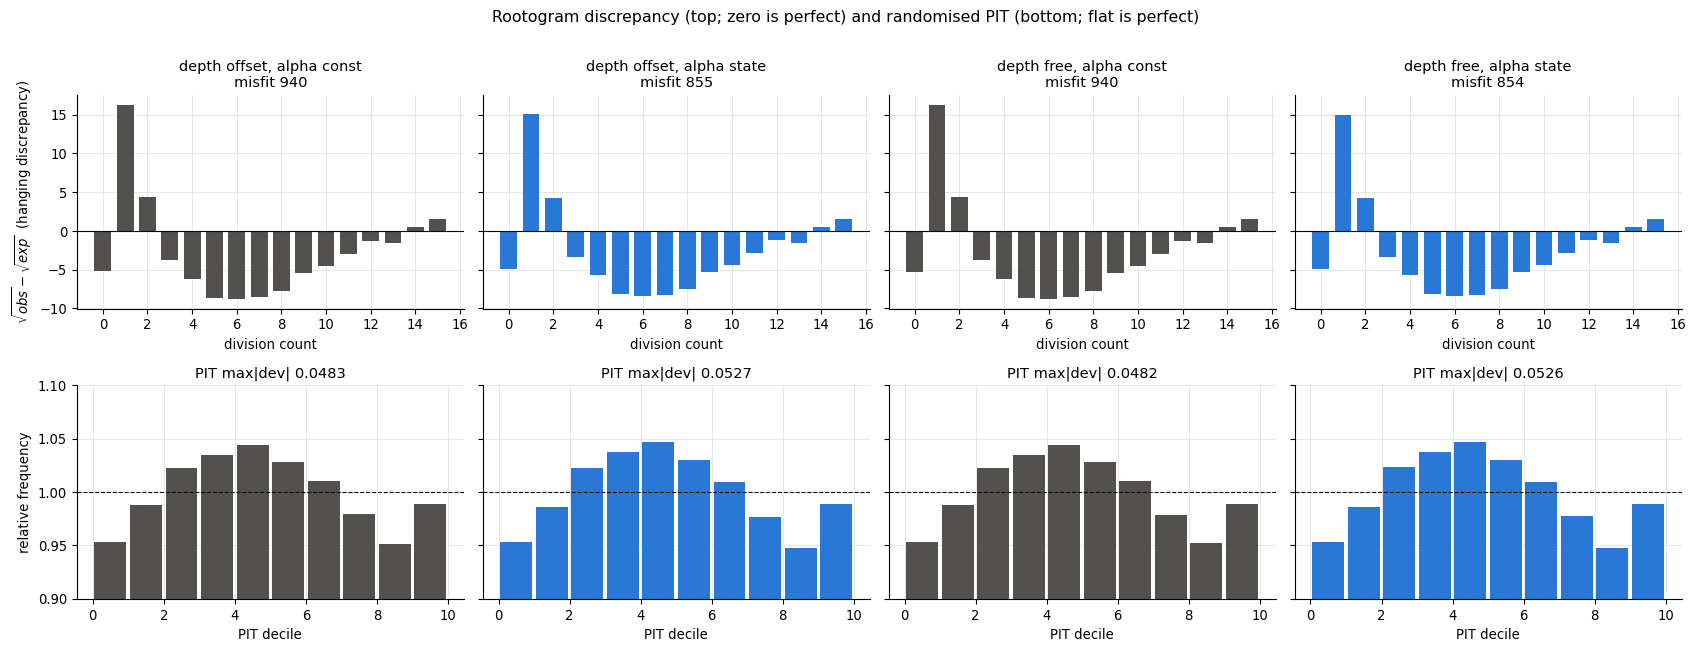

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.4), sharey="row")
KS = np.arange(16)
for j, key in enumerate(GRID):
    obs, exp_ = roots[key]
    d = np.sqrt(obs) - np.sqrt(exp_)
    ax = axes[0, j]
    ax.bar(KS, d[:16], width=0.75, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"depth {key[0]}, alpha {key[1]}\nmisfit {tune_tab.loc[key, 'rootogram_misfit']:.0f}")
    ax.set_xlabel("division count")
    u = nbb.pit(y, tune[key]["mu"], tune[key]["alpha"])
    h = np.histogram(u, 10, (0, 1))[0] / (n / 10)
    ax = axes[1, j]
    ax.bar(np.arange(10) + 0.5, h, width=0.9, color=COL["real"] if key[1] == "state" else COL["base"])
    ax.axhline(1, color=INK, lw=0.8, ls="--"); ax.set_ylim(0.9, 1.1)
    ax.set_xlabel("PIT decile"); ax.set_title(f"PIT max|dev| {tune_tab.loc[key, 'pit_maxdev']:.4f}")
axes[0, 0].set_ylabel(r"$\sqrt{obs}-\sqrt{exp}$  (hanging discrepancy)")
axes[1, 0].set_ylabel("relative frequency")
fig.suptitle("Rootogram discrepancy (top; zero is perfect) and randomised PIT (bottom; flat is perfect)", y=1.01)
fig.tight_layout(); savefig(fig, "tuning_calibration")

In [5]:
# Do the state coefficients depend on the depth specification? (old §21's stability check)
eff = {key: pd.concat({"own": nbb.state_effects(tune[key], basis, "a"),
                       "nbr": nbb.state_effects(tune[key], basis, "c")}) for key in GRID}
a_, b_ = eff[("offset", "const")], eff[("free", "const")]
stab = a_.join(b_, lsuffix="_offset", rsuffix="_free")
stab["shift_in_se"] = (stab["estimate_free"] - stab["estimate_offset"]) / stab["se_offset"]
print(f"own + neighbour effects, offset vs free depth: Pearson r = "
      f"{np.corrcoef(stab['estimate_offset'], stab['estimate_free'])[0, 1]:.5f}, "
      f"largest shift {stab['shift_in_se'].abs().max():.2f} SE")
stab[["estimate_offset", "estimate_free", "z_offset", "z_free", "shift_in_se"]].round(3)

own + neighbour effects, offset vs free depth: Pearson r = 1.00000, largest shift 0.02 SE


estimate_offset  estimate_free  z_offset  z_free  shift_in_se
own Endothelial                 -0.354         -0.354   -37.110 -37.042       -0.008
    CAFs                        -0.498         -0.498   -46.444 -46.422       -0.004
    PVL                         -0.121         -0.121    -8.781  -8.779        0.001
    B-cells                      0.386          0.386    31.477  31.415        0.008
    T-cells                      0.381          0.381    45.756  45.589        0.011
    Myeloid                     -0.248         -0.248   -28.637 -28.583        0.007
    Normal Epithelial           -0.116         -0.116   -10.004  -9.970       -0.012
    Plasmablasts                 0.037          0.037     2.291   2.294        0.005
    Cancer Epithelial            0.533          0.533    53.184  53.042       -0.009
nbr Endothelial                 -0.691         -0.690   -15.645 -15.562        0.012
    CAFs                        -0.106         -0.106    -3.035  -3.036       -0.002
    PVL                          0.050          0.050     0.909   0.911        0.001
    B-cells                     -0.053         -0.053    -1.339  -1.336        0.002
    T-cells                      0.174          0.174     7.085   7.004       -0.017
    Myeloid                     -0.130         -0.130    -3.561  -3.559        0.001
    Normal Epithelial           -0.433         -0.433    -7.206  -7.205        0.000
    Plasmablasts                 0.665          0.665     9.984   9.984        0.000
    Cancer Epithelial            0.523          0.523    15.539  15.487       -0.009

### The shape of the depth response

Three views of the offset assumption, all on constant-$\alpha$ fits:
- **left:** the spline model's deviation from the offset, with pointwise 95%
  bands, over the central 99% of $\log N$. The free-exponent line is drawn for
  comparison. A correct offset is flat at zero.
- **middle:** the depth exponent implied for each cell type by the per-type
  slope model, $1 + \bar\phi_k^\top t$, where $\bar\phi_k$ is the mean
  projected state of cells argmax-typed as $k$.
- **right:** observed over expected division counts in each decile of $\log N$
  under the offset model, with ±2 SE. A correct offset sits at 1 in every decile.

per-cell depth exponent under the per-type model: 5-95% range 0.786-1.311
largest spline deviation from the offset over the central 99% of log N: 0.466 on the log scale (59.4%)


,depth exponent,se
Normal Epithelial,0.863,0.005
CAFs,0.899,0.009
Endothelial,0.910,0.008
Plasmablasts,0.933,0.007
Cancer Epithelial,0.957,0.004
Myeloid,0.968,0.007
PVL,0.969,0.008
B-cells,1.118,0.009
T-cells,1.237,0.008


,median N,O/E offset,se,O/E spline
0,13.0,1.1391,0.0140,1.0180
1,21.0,1.0787,0.0109,1.0133
2,30.0,1.0119,0.0099,0.9813
3,40.0,1.0076,0.0085,0.9980
4,51.0,0.9786,0.0081,0.9839
5,65.0,0.9536,0.0072,0.9693
6,86.0,0.9723,0.0065,0.9969
7,125.0,0.9900,0.0058,1.0215
8,206.0,0.9751,0.0049,1.0097
9,385.0,1.0560,0.0044,1.0049


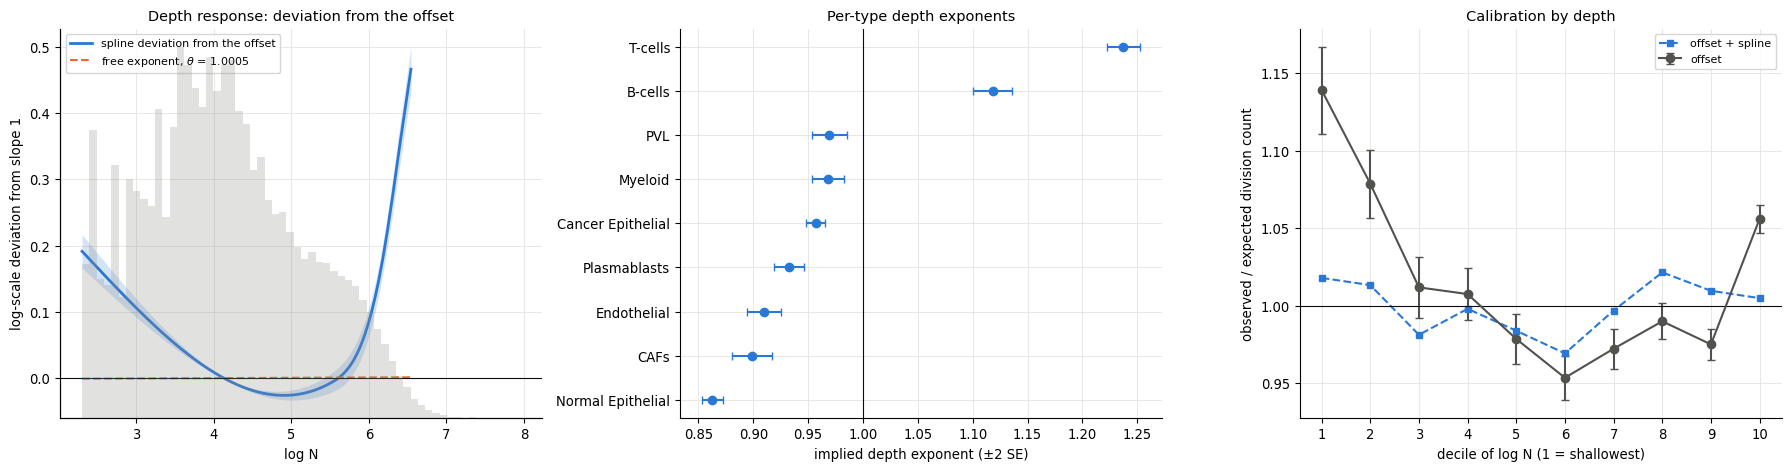

In [6]:
from tissue_dynamics.mixture.basis import _Spline
fo, fsp, fbt, ffr = tune[("offset", "const")], depth_fits["spline"], depth_fits["by_type"], tune[("free", "const")]
Nsp = _Spline(D["logN"], nbb.DEPTH_SPLINE_DF)          # the frozen basis load_design used
qN = np.quantile(D["logN"], np.linspace(0.005, 0.995, 200))
mN = D["logN"].mean()
v, Cv = nbb.estimate(fsp, "tN")
Bq = Nsp(qN) - Nsp(np.array([mN]))                      # deviation, pinned to 0 at mean log N
dev, dev_se = Bq @ v, np.sqrt(np.einsum("ij,jk,ik->i", Bq, Cv, Bq))
th_free = float(ffr["params"]["theta"])

vt, Ct = nbb.estimate(fbt, "tT")
slopes = pd.DataFrame({t: {"depth exponent": 1 + D["own"][ctype == t].mean(0) @ vt,
                           "se": float(np.sqrt(D["own"][ctype == t].mean(0) @ Ct @ D["own"][ctype == t].mean(0)))}
                       for t in TYPES}).T.sort_values("depth exponent")
cell_slope = 1 + D["own"] @ vt
print(f"per-cell depth exponent under the per-type model: 5-95% range "
      f"{np.percentile(cell_slope, 5):.3f}-{np.percentile(cell_slope, 95):.3f}")

dec = pd.qcut(D["logN"], 10, labels=False)
def oe(f):
    mu, a = f["mu"], f["alpha"]
    var = mu + (a if np.isscalar(a) else a) * mu ** 2
    o = np.bincount(dec, weights=y); e = np.bincount(dec, weights=mu); v_ = np.bincount(dec, weights=var)
    return o / e, np.sqrt(v_) / e
oe_off, oe_off_se = oe(fo); oe_sp, _ = oe(fsp)
dec_tab = pd.DataFrame({"median N": [np.median(df["N"].to_numpy()[dec == k]) for k in range(10)],
                        "O/E offset": oe_off, "se": oe_off_se, "O/E spline": oe_sp})
print(f"largest spline deviation from the offset over the central 99% of log N: "
      f"{np.max(np.abs(dev)):.3f} on the log scale ({100 * (np.exp(np.max(np.abs(dev))) - 1):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.fill_between(qN, dev - 2 * dev_se, dev + 2 * dev_se, color=COL["real"], alpha=0.2, lw=0)
ax.plot(qN, dev, color=COL["real"], lw=2, label="spline deviation from the offset")
ax.plot(qN, (th_free - 1) * (qN - mN), "--", color=COL["decoy"], label=rf"free exponent, $\theta$ = {th_free:.4f}")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xlabel("log N"); ax.set_ylabel("log-scale deviation from slope 1"); ax.legend(fontsize=8)
ax.set_title("Depth response: deviation from the offset")
ax2 = ax.twinx(); ax2.hist(D["logN"], bins=60, color=MUTED, alpha=0.25); ax2.set_yticks([]); ax2.grid(False)
ax = axes[1]
ax.errorbar(slopes["depth exponent"], np.arange(len(slopes)), xerr=2 * slopes["se"], fmt="o",
            color=COL["real"], capsize=3)
ax.axvline(1, color=INK, lw=0.8); ax.set_yticks(np.arange(len(slopes))); ax.set_yticklabels(slopes.index)
ax.set_xlabel("implied depth exponent (±2 SE)"); ax.set_title("Per-type depth exponents")
ax = axes[2]
ax.errorbar(np.arange(10) + 1, oe_off, yerr=2 * oe_off_se, fmt="o-", color=COL["base"], capsize=3, label="offset")
ax.plot(np.arange(10) + 1, oe_sp, "s--", color=COL["real"], ms=4, label="offset + spline")
ax.axhline(1, color=INK, lw=0.8); ax.set_xticks(np.arange(10) + 1)
ax.set_xlabel("decile of log N (1 = shallowest)"); ax.set_ylabel("observed / expected division count")
ax.set_title("Calibration by depth"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "depth_offset_tests")
display(slopes.round(3)); dec_tab.round(4)

In [7]:
# Dispersion submodel: which cell types are over- or under-dispersed?
th_d = "offset"
fs, fc = tune[(th_d, "state")], tune[(th_d, "const")]
g = nbb.state_effects(fs, basis, "gamma")
g["exp(gamma)"] = np.exp(g["estimate"])
rc = nbb.rootogram(y, fc["mu"], fc["alpha"], groups=ctype)
rs = nbb.rootogram(y, fs["mu"], fs["alpha"], groups=ctype)
per = pd.DataFrame({t: {"cells": int((ctype == t).sum()),
                        "median alpha_i": float(np.median(fs["alpha"][ctype == t])),
                        "misfit, constant": nbb.misfit(*rc[t]), "misfit, state": nbb.misfit(*rs[t])}
                    for t in TYPES}).T
per["change %"] = 100 * (per["misfit, state"] / per["misfit, constant"] - 1)
print(f"constant alpha {fc['alpha']:.4f}; state alpha_i median {np.median(fs['alpha']):.4f}, "
      f"IQR {np.percentile(fs['alpha'], 25):.4f}-{np.percentile(fs['alpha'], 75):.4f}")
g[["exp(gamma)", "estimate", "se", "z"]].join(per).sort_values("exp(gamma)").round(3)

constant alpha 0.7591; state alpha_i median 0.7390, IQR 0.6822-0.7880


,exp(gamma),estimate,se,z,cells,median alpha_i,"misfit, constant","misfit, state",change %
CAFs,0.737,-0.305,0.040,-7.595,52506.0,0.562,66.216,37.330,-43.623
Normal Epithelial,0.820,-0.198,0.035,-5.698,53149.0,0.688,196.246,171.339,-12.691
Plasmablasts,0.895,-0.111,0.044,-2.498,42228.0,0.688,63.247,54.494,-13.839
B-cells,1.006,0.006,0.034,0.191,57825.0,0.712,118.371,108.955,-7.955
PVL,1.054,0.053,0.045,1.180,40175.0,0.734,39.516,36.630,-7.302
T-cells,1.059,0.058,0.022,2.665,89213.0,0.746,279.858,274.265,-1.999
Endothelial,1.067,0.065,0.031,2.094,47810.0,0.750,63.752,62.679,-1.683
Myeloid,1.171,0.158,0.028,5.682,68186.0,0.786,90.553,93.801,3.586
Cancer Epithelial,1.316,0.275,0.022,12.608,110805.0,0.792,708.452,722.964,2.048


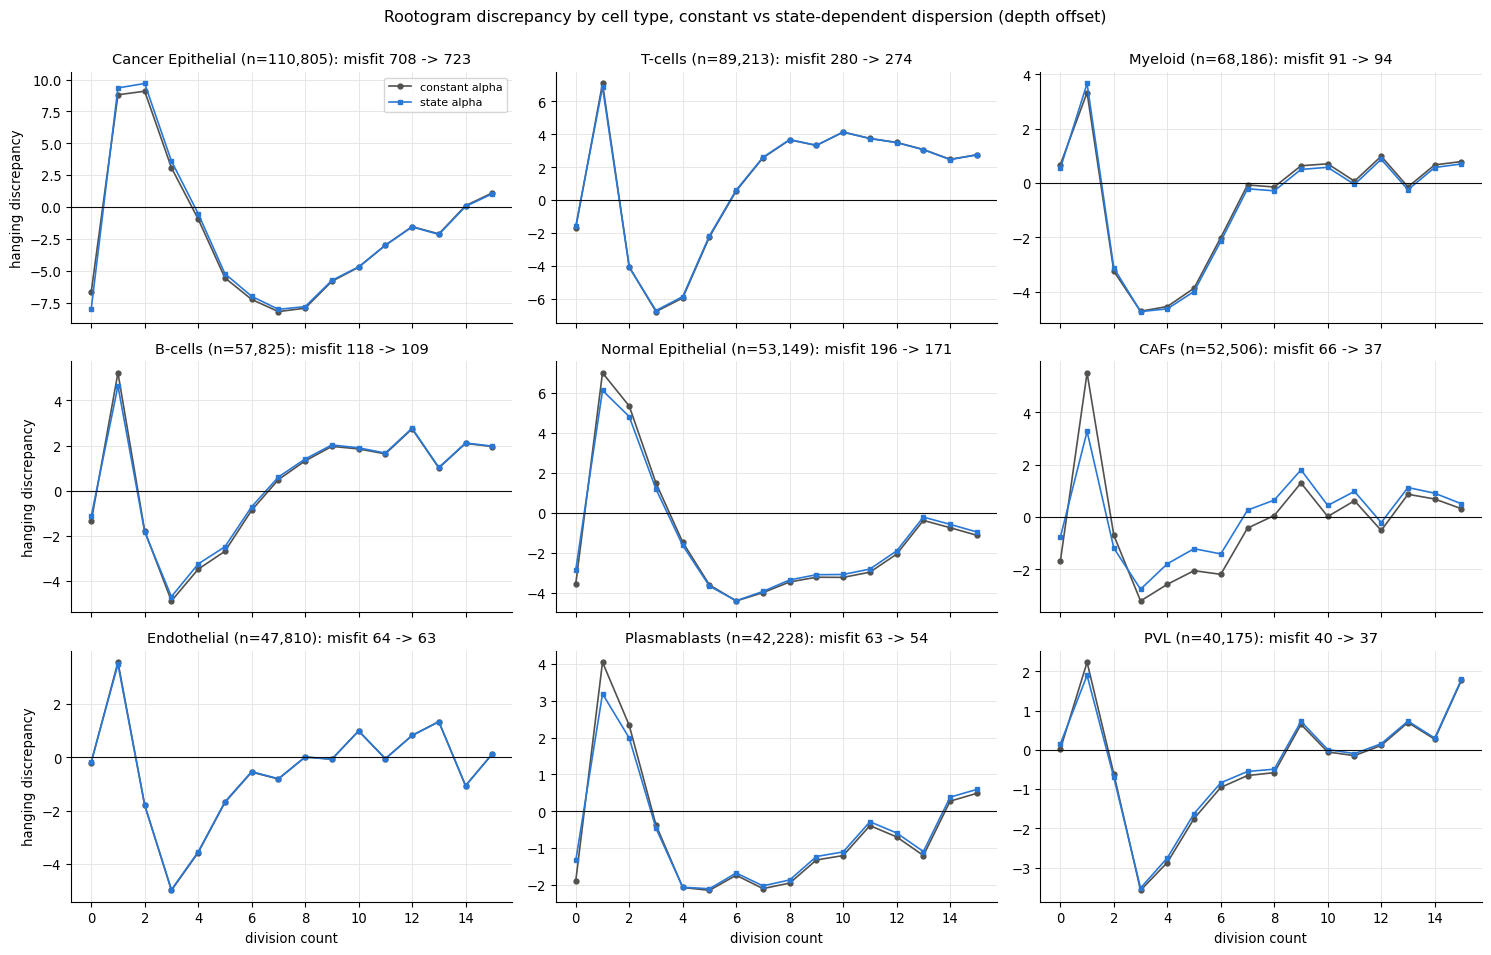

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9.5), sharex=True)
for ax, t in zip(axes.ravel(), sorted(TYPES, key=lambda t: -(ctype == t).sum())):
    for lab, R, c, m in (("constant alpha", rc, COL["base"], "o"), ("state alpha", rs, COL["real"], "s")):
        o, e = R[t]
        ax.plot(KS, (np.sqrt(o) - np.sqrt(e))[:16], m + "-", ms=3.5, lw=1.2, color=c, label=lab)
    ax.axhline(0, color=INK, lw=0.8)
    ax.set_title(f"{t} (n={(ctype == t).sum():,}): misfit {per.loc[t, 'misfit, constant']:.0f} "
                 f"-> {per.loc[t, 'misfit, state']:.0f}")
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("division count")
for ax in axes[:, 0]: ax.set_ylabel("hanging discrepancy")
fig.suptitle("Rootogram discrepancy by cell type, constant vs state-dependent dispersion (depth offset)", y=1.0)
fig.tight_layout(); savefig(fig, "tuning_dispersion_by_type")

### Reading §2

**On average, depth enters exactly proportionally.** The free exponent is
$\hat\theta = 1.0005$ (SE 0.004). Freeing it gains 0.01 log-likelihood units, and
no own or neighbour effect moves by more than 0.02 SE.

**But not across the whole range, and not for every cell type.**
- **Spline.** A spline deviation from the offset gains 1,192 units on 5 df and
  cuts rootogram misfit by 32% (940 to 641). Under the offset, observed/expected
  is 1.14 in the shallowest decile (median N = 13), 0.95–1.0 in the middle and
  1.06 in the deepest (median N = 385). The spline flattens that to 0.97–1.02.
- **Per-type slopes.** They gain 1,884 units on 8 df. Implied exponents run from
  0.86 (Normal Epithelial) to 1.24 (T-cells), but rootogram misfit improves by
  only 2%.

Neither departure is a reason to free depth. The shallow-cell excess looks like
an *additive* background (ambient or spilled transcripts, which matter most
where N is small), and the mixture's Stage C term models exactly that. The
deep-cell and per-type slopes are likely biology leaking into the technical
term, because cycling cells carry more RNA. A flexible depth term would absorb
division signal. **Decision (user, 2026-10-06): the offset stays.** Testing Stage C
for the shallow-cell excess is an open item.

**State-dependent dispersion helps the marginal fit, not calibration.**
- LR 290 on 8 df; rootogram misfit falls 9%.
- The gain sits mostly in CAFs (−44%), Normal Epithelial (−13%) and
  Plasmablasts (−14%). Cancer Epithelial (+2%) and Myeloid (+4%) get slightly
  worse.
- The PIT worsens (0.048 to 0.053), and residual Moran's I is unchanged.
- Over-dispersed types: Cancer Epithelial ($e^\gamma$ = 1.32) and Myeloid
  (1.17). Under-dispersed: CAFs (0.74) and Normal Epithelial (0.82).

Every specification keeps the same shape defect: an excess at count 1 and a
deficit at counts 4–9. The mixture exists to fix that.

**Baseline for §3–5: offset, constant $\alpha$, no oxygen.** The reasoning and
the decision log are in the [specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077).

In [9]:
BASE = dict(theta="offset", dispersion="const")    # the decision above
base_fit = tune[(BASE["theta"], BASE["dispersion"])]
print("baseline:", BASE, "| no oxygen term |", f"loglik {base_fit['loglik']:,.1f} | "
      f"alpha {base_fit['alpha']:.4f} | {nbb.n_params(base_fit['params'])} parameters")

baseline: {'theta': 'offset', 'dispersion': 'const'} | no oxygen term | loglik -597,503.0 | alpha 0.7591 | 102 parameters


## 3. The oxygen field

**Status: dropped.** On the evidence below, $\psi\,u$ was removed from every
model on 2026-10-06 (`model.oxygen: false`). The baseline has no oxygen term,
and this section adds it back only to test it.

The field is a steady-state screened-diffusion solve over the rasterised
section (`tissue_dynamics.oxygen`):

$$\nabla^2 u = \kappa(x)\,u, \qquad -\nabla u\cdot\hat n = \beta\,\Phi(x)\,(1-u).$$

$\Phi$ marks the endothelial source cells. Consumption
$\kappa = (1/L_0^2)(n/n_0)$ rises with local density, so $L_0$ is the screening
length at reference density: roughly how far oxygen reaches from a vessel. $u$
is scale-free relative oxygenation in $[0,1]$, not pO₂.

**What changed.** The source is now the log1p Endothelial score of typed cells
($N \ge 10$). The top 2.6% after z-scoring are sources, at grid pitch 5 µm,
$L_0 = 100$ µm and $\beta = 1$. The old field came from the SpaNorm minor
table, whose endothelial columns tracked depth. It did not mark vessels: AUROC
0.515 for marker-identified endothelium. Every oxygen result in the old
notebook therefore needs redoing, including:
- the ~13× margin over the rotated decoy;
- the $L_0$ optimum at 100–200 µm;
- the HIF failure.

One deviation to keep in mind: the major-table Endothelial column includes
lymphatic endothelium, which carries no oxygenated blood. The old source
excluded it.

The plan:
1. Rebuild the field and check that it reproduces the table column.
2. Test that its source marks vessels.
3. Rerun the HIF-marker gate.
4. Test whether $u$ explains division beyond cell state, against three decoys,
   at every $L_0$ in the sweep.

In [10]:
cells = nbb.cached("all_cells", lambda: nbb.all_cells(cfg))
src_xy, src_score = nbb.oxygen_source(cells, cfg)
txy = df[["x", "y"]].to_numpy(float)
L0S = (50.0, 100.0, 200.0, 400.0, 800.0)

f100 = nbb.cached("field_L100", lambda: nbb.field_samples(txy, src_xy, src_score, 100.0, cfg,
                                                          keep_raster=True))
print(f"{len(cells):,} cells with PhiSpace scores, {cells['typed'].sum():,} typed; "
      f"{(src_score > 0).sum():,} sources ({100 * (src_score > 0).mean():.2f}% of typed cells)")
print(f"reproduces the table's oxygen column: max |difference| = "
      f"{np.nanmax(np.abs(f100['u'] - df['oxygen'].to_numpy())):.1e}")

# zoom window: the 2.5 mm square (500 px) where u varies most, among windows >= 95% tissue
R = f100["raster"]; blk, wb = 100, 5
best, WIN = -1.0, None
for a in range(R.shape[0] // blk - wb + 1):
    for b in range(R.shape[1] // blk - wb + 1):
        w = R[a * blk:(a + wb) * blk, b * blk:(b + wb) * blk]
        if np.isfinite(w).mean() >= 0.95 and np.nanstd(w) > best:
            best, WIN = float(np.nanstd(w)), ((a * blk, (a + wb) * blk), (b * blk, (b + wb) * blk))

fields = {}
for L0 in L0S:
    F = f100 if L0 == 100.0 else nbb.cached(f"field_L{int(L0)}", lambda L0=L0: nbb.field_samples(
        txy, src_xy, src_score, L0, cfg, keep_raster=True))
    fields[L0] = dict(F, window=F["raster"][WIN[0][0]:WIN[0][1], WIN[1][0]:WIN[1][1]])
xa, sa = nbb.oxygen_source(cells, cfg, consumers="all")
f_all = nbb.cached("field_L100_allconsumers", lambda: nbb.field_samples(txy, xa, sa, 100.0, cfg))

rows = []
for L0, F in fields.items():
    u, d = F["u"], F["diagnostics"]; ok = np.isfinite(u)
    rows.append({"L0": L0, "unknowns": d["n_unknowns"], "rel_residual": d["rel_residual"],
                 "mean u": np.nanmean(u), "sd u": np.nanstd(u),
                 "corr(u, log N)": np.corrcoef(u[ok], logN[ok])[0, 1],
                 "corr(u, log density)": np.corrcoef(u[ok], np.log(df["density"].to_numpy())[ok])[0, 1],
                 "solve min": F["minutes"]})
field_tab = pd.DataFrame(rows).set_index("L0")
ok = np.isfinite(f_all["u"]) & np.isfinite(f100["u"])
print(f"variant where shallow cells also consume oxygen: corr with production {np.corrcoef(f_all['u'][ok], f100['u'][ok])[0, 1]:.4f}, "
      f"mean u {np.nanmean(f_all['u']):.3f} vs {np.nanmean(f100['u']):.3f}")
field_tab

683,218 cells with PhiSpace scores, 564,004 typed; 14,665 sources (2.60% of typed cells)
reproduces the table's oxygen column: max |difference| = 1.1e-09


variant where shallow cells also consume oxygen: corr with production 0.9754, mean u 0.310 vs 0.333


,unknowns,rel_residual,mean u,sd u,"corr(u, log N)","corr(u, log density)",solve min
L0,,,,,,,
50.0,4501235,8.6586e-11,0.1312,0.1247,-0.0840,-0.2222,0.3118
100.0,4501235,9.5301e-11,0.3335,0.1671,-0.0966,-0.2700,0.3686
200.0,4501235,8.0096e-11,0.6314,0.1493,-0.0874,-0.2609,0.3683
400.0,4501235,7.1389e-11,0.8598,0.0900,-0.0601,-0.1818,0.3572
800.0,4501235,9.1375e-11,0.9576,0.0480,-0.0235,-0.0567,0.3951


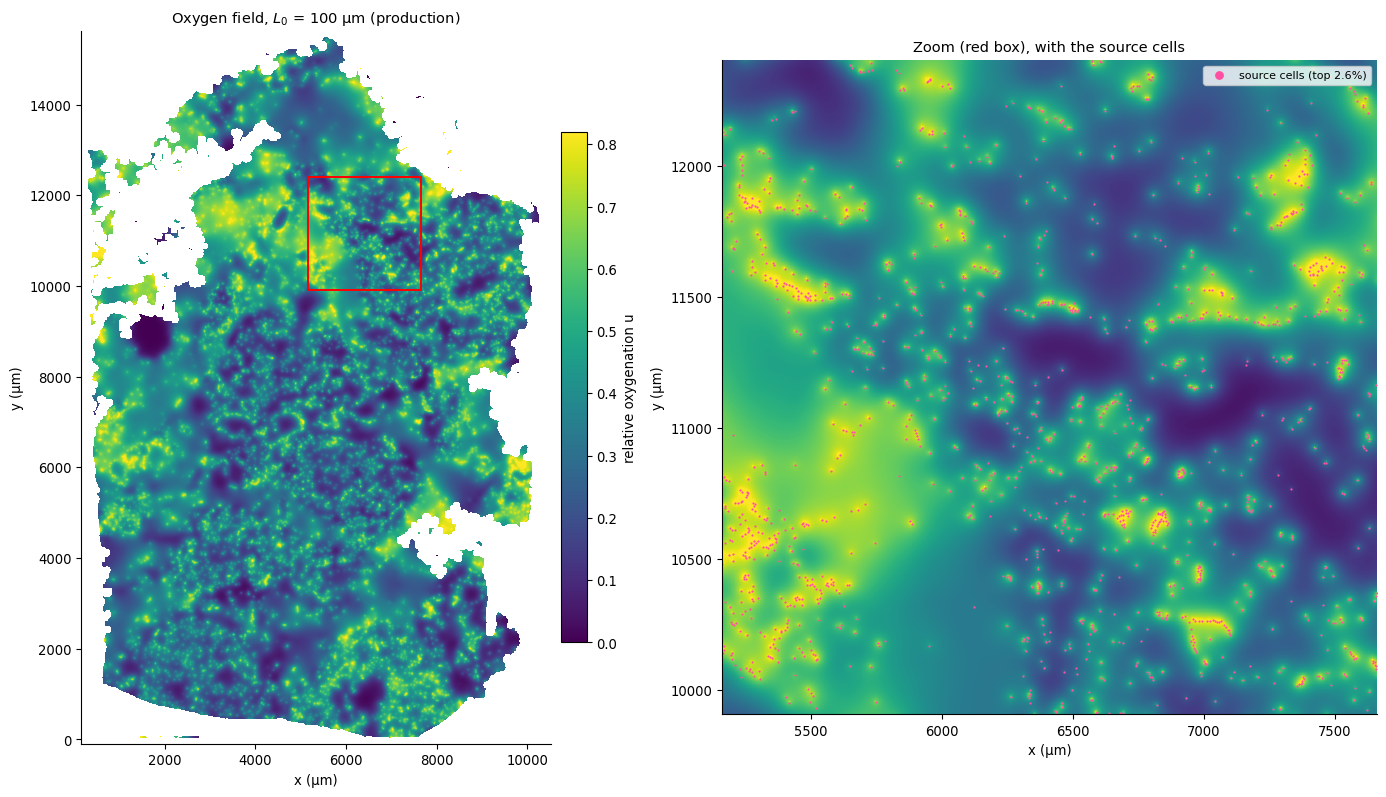

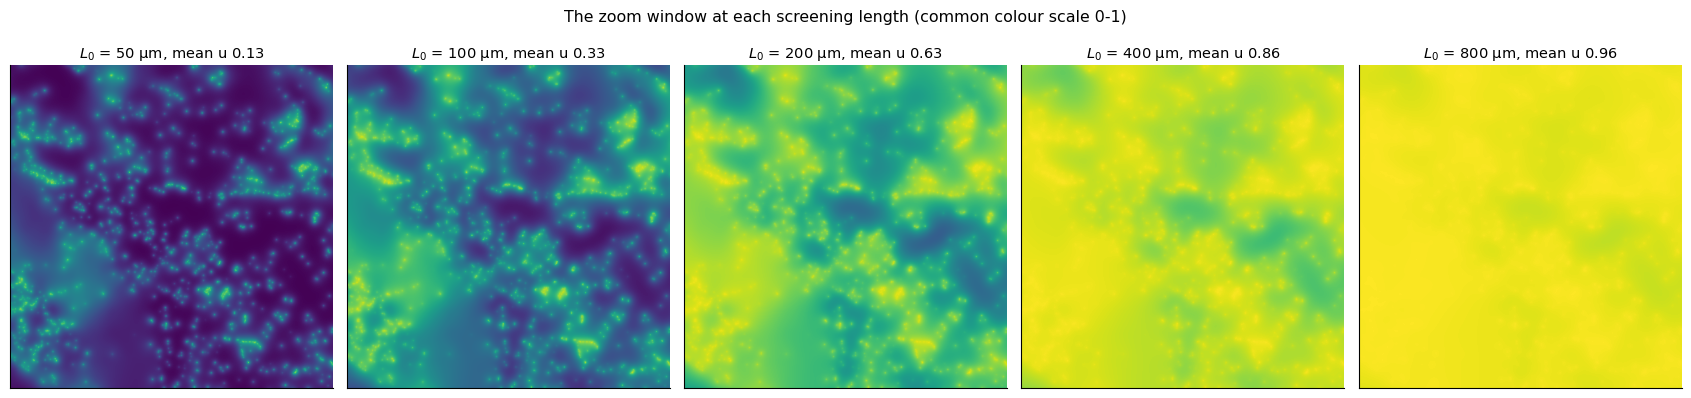

In [11]:
org, h = f100["origin"], f100["h"]
ext = [org[0], org[0] + R.shape[0] * h, org[1], org[1] + R.shape[1] * h]
(wi0, wi1), (wj0, wj1) = WIN
zext = [org[0] + wi0 * h, org[0] + wi1 * h, org[1] + wj0 * h, org[1] + wj1 * h]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [0.78, 1]})
im = ax.imshow(R.T, origin="lower", extent=ext, cmap="viridis", vmin=0, vmax=np.nanpercentile(R, 99.5))
ax.add_patch(plt.Rectangle((zext[0], zext[2]), zext[1] - zext[0], zext[3] - zext[2], fill=False, ec="red", lw=1.4))
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label="relative oxygenation u")
ax.set_title(r"Oxygen field, $L_0$ = 100 µm (production)"); ax.grid(False)
ax = ax2
w = fields[100.0]["window"]
ax.imshow(w.T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=np.nanpercentile(w, 99.5))
s = (src_score > 0) & (src_xy[:, 0] > zext[0]) & (src_xy[:, 0] < zext[1]) & (src_xy[:, 1] > zext[2]) & (src_xy[:, 1] < zext[3])
ax.scatter(src_xy[s, 0], src_xy[s, 1], s=2.5, c="#ff4fa3", lw=0, label="source cells (top 2.6%)")
ax.legend(loc="upper right", fontsize=8, markerscale=4); ax.set_title("Zoom (red box), with the source cells"); ax.grid(False)
for a in (fig.axes[0], ax2): a.set_xlabel("x (µm)"); a.set_ylabel("y (µm)")
fig.tight_layout(); savefig(fig, "oxygen_field_maps")

fig, axes = plt.subplots(1, len(L0S), figsize=(17, 3.9))
for ax, L0 in zip(axes, L0S):
    ax.imshow(fields[L0]["window"].T, origin="lower", extent=zext, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(rf"$L_0$ = {L0:.0f} µm, mean u {field_tab.loc[L0, 'mean u']:.2f}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("The zoom window at each screening length (common colour scale 0-1)", y=1.02)
fig.tight_layout(); savefig(fig, "oxygen_field_by_L0")

### 3.1 Does the source mark vessels?

A field is only as good as its source. Marker-identified endothelium is used as
ground truth that does not depend on PhiSpace:
- **positives:** cells with ≥ 2 PECAM1 + CDH5 + CLDN5 counts, at least 3× their
  epithelial, T-cell, fibroblast and macrophage marker counts;
- **negatives:** cells with no endothelial counts and ≥ 3 other-lineage counts.

The AUROC asks how well a variable separates the two groups, scored at the
cells themselves. For $u$ that should be high, because endothelial cells sit at
the field's maxima. The decoys should score about 0.5.

In [12]:
gc_ = cells.set_index("cell_id").reindex(df["cell_id"])
endo_ct = gc_[[f"g_{m}" for m in nbb.ENDO_MARKERS]].sum(1).to_numpy()
other_ct = gc_[[f"g_{m}" for m in nbb.OTHER_MARKERS]].sum(1).to_numpy()
pos, neg = (endo_ct >= 2) & (endo_ct >= 3 * other_ct), (endo_ct == 0) & (other_ct >= 3)
print(f"marker endothelium {pos.sum():,} cells; marker-negative {neg.sum():,}")

def auroc(v):
    ok = np.isfinite(v) & (pos | neg)
    return roc_auc_score(pos[ok], v[ok])

auc = {"Endothelial PhiSpace score (the source)": auroc(gc_["phi_Endothelial"].to_numpy())}
for L0 in L0S:
    auc[f"u, L0 = {L0:.0f}"] = auroc(fields[L0]["u"])
for k in nbb.DECOYS:
    auc[f"decoy {k}, L0 = 100"] = auroc(f100["decoys"][k])
auc["u, L0 = 100, shallow cells also consume"] = auroc(f_all["u"])
auc_tab = pd.Series(auc, name="AUROC").to_frame()
auc_tab["(old SpaNorm field: 0.515)"] = ""
auc_tab.round(3)

marker endothelium 2,252 cells; marker-negative 27,973


,AUROC,(old SpaNorm field: 0.515)
Endothelial PhiSpace score (the source),0.985,
"u, L0 = 50",0.823,
"u, L0 = 100",0.788,
"u, L0 = 200",0.754,
"u, L0 = 400",0.735,
"u, L0 = 800",0.729,
"decoy rot180, L0 = 100",0.499,
"decoy flip_x, L0 = 100",0.507,
"decoy flip_y, L0 = 100",0.493,
"u, L0 = 100, shallow cells also consume",0.791,


### 3.2 The HIF-marker gate

The old §17 test, rerun on the new field: tile the section at 100 µm and ask
whether hypoxia-target expression falls where modelled oxygenation is high.
- Tiles need ≥ 20 cells.
- Rates are HIF-target transcripts per 1,000 total transcripts in the tile.
- The *partial* correlation ranks out tile depth, which inflated the old rates
  in shallow tissue.

The old core set had six genes. The Prime panel also carries a further ten
canonical HIF targets, used as an extended set. A clearly negative correlation
would license $u$ as a hypoxia proxy. A null is what the old notebook found,
and there it was blamed on the readout's sparsity.

In [13]:
genes_core = [g for g in nbb.HIF_CORE if f"g_{g}" in cells]
genes_ext = genes_core + [g for g in nbb.HIF_EXTENDED if f"g_{g}" in cells]
Tt = nbb.tiles(xc, yc, tile=100.0, min_cells=20)
tsum = lambda v: np.bincount(Tt["inv"], weights=v)[Tt["keep"]]
tot_t = tsum(gc_["total"].to_numpy(float))
logN_t = tsum(logN) / Tt["count"]

def partial_spearman(a, b, z):
    ra, rb, rz = (stats.rankdata(v) for v in (a, b, z))
    res = lambda v: v - np.polyval(np.polyfit(rz, v, 1), rz)
    return np.corrcoef(res(ra), res(rb))[0, 1]

rows = []
for lab, gl in (("core 6", genes_core), (f"extended {len(genes_ext)}", genes_ext)):
    rate = 1000 * tsum(gc_[[f"g_{g}" for g in gl]].sum(1).to_numpy(float)) / tot_t
    for L0 in L0S:
        ut = tsum(np.nan_to_num(fields[L0]["u"], nan=np.nanmean(fields[L0]["u"]))) / Tt["count"]
        rows.append({"genes": lab, "L0": L0, "Spearman(u, HIF rate)": stats.spearmanr(ut, rate).statistic,
                     "partial, depth ranked out": partial_spearman(ut, rate, logN_t)})
    rows.append({"genes": lab, "L0": "-", "Spearman(u, HIF rate)": stats.spearmanr(logN_t, rate).statistic,
                 "partial, depth ranked out": np.nan, "note": "row = Spearman(tile depth, HIF rate)"})
hif_tab = pd.DataFrame(rows)
print(f"{Tt['keep'].sum():,} tiles with >= 20 cells (median {np.median(Tt['count']):.0f} cells)")
per_gene = pd.DataFrame({g: {"cells detected %": 100 * (gc_[f"g_{g}"] > 0).mean(),
                             "tiles with zero %": 100 * (tsum(gc_[f"g_{g}"].to_numpy(float)) == 0).mean(),
                             "Spearman(u100, rate)": stats.spearmanr(
                                 tsum(np.nan_to_num(f100["u"])) / Tt["count"],
                                 tsum(gc_[f"g_{g}"].to_numpy(float)) / tot_t).statistic}
                         for g in genes_ext}).T
display(hif_tab.round(4)); per_gene.round(3)

7,624 tiles with >= 20 cells (median 64 cells)


,genes,L0,"Spearman(u, HIF rate)","partial, depth ranked out",note
0,core 6,50.0,0.2719,0.2336,NaN
1,core 6,100.0,0.2664,0.2244,NaN
2,core 6,200.0,0.2525,0.2104,NaN
3,core 6,400.0,0.2421,0.2011,NaN
4,core 6,800.0,0.2374,0.1971,NaN
5,core 6,-,-0.3669,NaN,"row = Spearman(tile depth, HIF rate)"
6,extended 16,50.0,0.2027,0.1507,NaN
7,extended 16,100.0,0.1974,0.1405,NaN
8,extended 16,200.0,0.1860,0.1291,NaN
9,extended 16,400.0,0.1782,0.1228,NaN


,cells detected %,tiles with zero %,"Spearman(u100, rate)"
CA9,0.242,84.942,-0.086
NDRG1,5.306,11.988,0.229
ADM,1.239,55.155,0.068
EGLN3,0.642,66.041,0.012
BNIP3,1.294,54.499,-0.149
ANGPTL4,0.716,67.550,0.085
VEGFA,7.177,10.113,0.072
SLC2A1,3.997,31.676,-0.194
PGK1,4.459,16.330,-0.013
LDHA,14.007,2.886,0.118


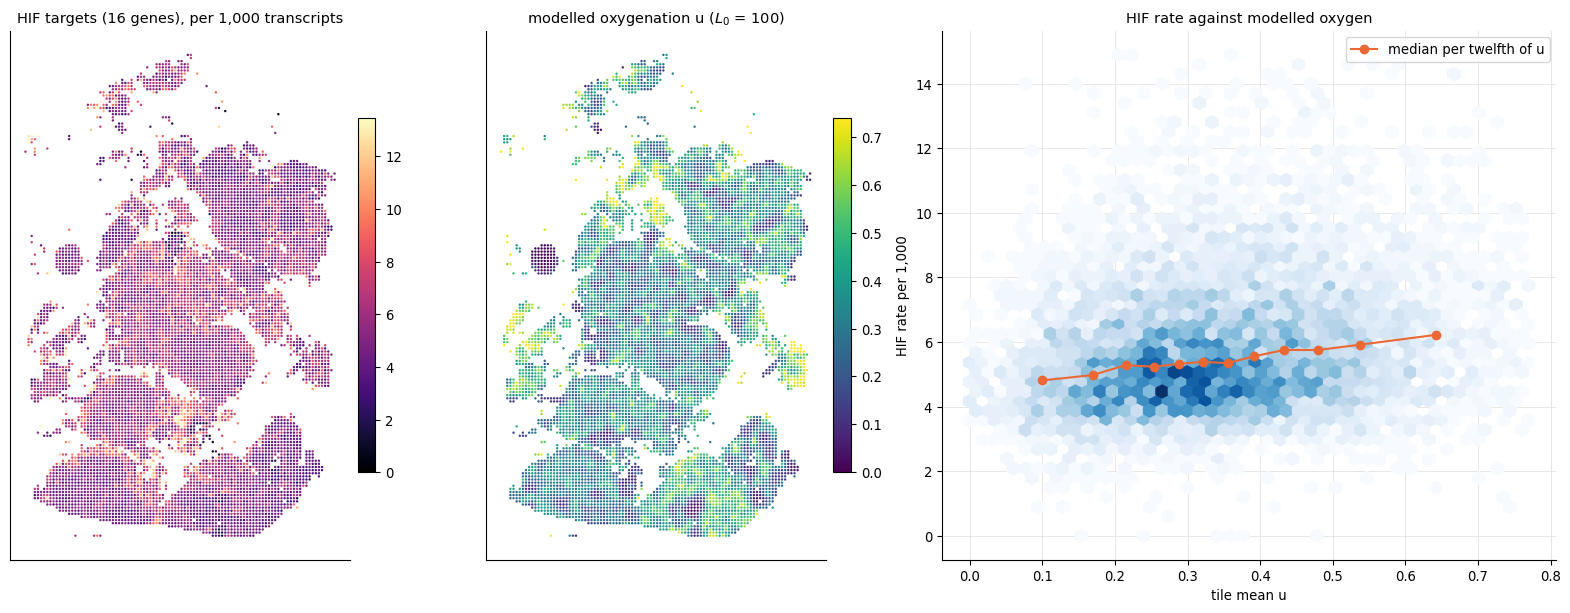

In [14]:
rate_ext = 1000 * tsum(gc_[[f"g_{g}" for g in genes_ext]].sum(1).to_numpy(float)) / tot_t
ut100 = tsum(np.nan_to_num(f100["u"])) / Tt["count"]
fig, axes = plt.subplots(1, 3, figsize=(16, 6.2), gridspec_kw={"width_ratios": [0.72, 0.72, 1.15]})
for ax, v, lab, cm in ((axes[0], rate_ext, f"HIF targets ({len(genes_ext)} genes), per 1,000 transcripts", "magma"),
                       (axes[1], ut100, r"modelled oxygenation u ($L_0$ = 100)", "viridis")):
    sc_ = ax.scatter(Tt["xy"][:, 0], Tt["xy"][:, 1], c=v, s=3, lw=0, cmap=cm,
                     vmin=0, vmax=np.percentile(v, 99))
    fig.colorbar(sc_, ax=ax, fraction=0.046, pad=0.02); ax.set_aspect("equal"); ax.set_title(lab)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax = axes[2]
ax.hexbin(ut100, rate_ext, gridsize=45, cmap="Blues", mincnt=1,
          extent=(0, np.percentile(ut100, 99.5), 0, np.percentile(rate_ext, 99.5)))
q = pd.qcut(ut100, 12, duplicates="drop")
med = pd.DataFrame({"u": ut100, "r": rate_ext}).groupby(q, observed=True).median()
ax.plot(med["u"], med["r"], "o-", color=COL["decoy"], label="median per twelfth of u")
ax.set_xlabel("tile mean u"); ax.set_ylabel("HIF rate per 1,000"); ax.legend(); ax.set_title("HIF rate against modelled oxygen")
fig.tight_layout(); savefig(fig, "oxygen_hif_gate")

### 3.3 Does $u$ explain division beyond cell state? Decoys and the $L_0$ sweep

The old §18 and §20, rerun with three decoys instead of one. Any smooth spatial
covariate soaks up some residual autocorrelation for free. So $u$ is judged
against the same raster:
- rotated 180° (point-reflected through the raster centre);
- mirrored in x;
- mirrored in y.

Each decoy has identical smoothness and marginal distribution, but is
misaligned with the tissue.

Every fit runs on one common cell set: cells inside the tissue mask under the
real field, all three decoys, and the all-consumers variant. That keeps every
likelihood and Moran's I comparable. The mask does not depend on $L_0$.

Each covariate is z-scored, so $\psi$ is the effect per SD of $u$ and is
comparable across $L_0$. The reference fit is the baseline on the common set, which has no oxygen term.
Each row of the table is one fit with one covariate added. Two measures compare real and
decoy:
- the drop in residual Moran's I, at the 100 µm tile scale;
- the likelihood gain.

In [15]:
valid = np.isfinite(f_all["u"])
for L0, F in fields.items():
    valid &= np.isfinite(F["u"])
    for k in nbb.DECOYS:
        valid &= np.isfinite(F["decoys"][k])
O = np.flatnonzero(valid)
T_O = nbb.tiles(xc[O], yc[O])
zs = lambda v: (v - v.mean()) / v.std()
print(f"common oxygen cell set: {len(O):,} cells ({100 * len(O) / n:.1f}%), {T_O['keep'].sum():,} tiles")

ox_base = nbb.cached("ox_base", lambda: nbb.fit(nbb.subset(D, O), init=base_fit["params"],
                                                say=print, **BASE, **PEN))
COVS = {(L0, kind): (fields[L0]["u"] if kind == "real" else fields[L0]["decoys"][kind])
        for L0 in L0S for kind in ("real",) + nbb.DECOYS}
COVS[(100.0, "all consumers")] = f_all["u"]
ox = {}
for (L0, kind), v in COVS.items():
    tag = f"ox_L{int(L0)}_{kind.replace(' ', '_')}"
    ox[(L0, kind)] = nbb.cached(tag, lambda v=v: nbb.fit(nbb.subset(D, O, oxygen=zs(v[O])),
                                                          init=ox_base["params"], say=print, **BASE, **PEN))

common oxygen cell set: 390,545 cells (69.5%), 7,100 tiles


In [16]:
yO = y[O]
I_base = nbb.tile_moran(nbb.pearson(yO, ox_base["mu"], ox_base["alpha"]), T_O, permutations=0)["I"]
rows = []
for (L0, kind), f in ox.items():
    v = COVS[(L0, kind)][O]
    psi, C = nbb.estimate(f, "psi")
    I = nbb.tile_moran(nbb.pearson(yO, f["mu"], f["alpha"]), T_O, permutations=0)["I"]
    rows.append({"L0": L0, "covariate": kind, "psi per SD": psi[0], "se": np.sqrt(C[0, 0]),
                 "z": psi[0] / np.sqrt(C[0, 0]), "LR vs no oxygen": 2 * (f["loglik"] - ox_base["loglik"]),
                 "resid Moran I": I, "Moran reduction": I_base - I,
                 "corr(cov, log N)": np.corrcoef(v, logN[O])[0, 1], "converged": f["info"]["converged"],
                 "attempts": f["info"].get("attempts", 1)})
ox_tab = pd.DataFrame(rows)
dec = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)].groupby("L0")
real = ox_tab[ox_tab["covariate"] == "real"].set_index("L0")
sweep = pd.DataFrame({
    "psi per SD": real["psi per SD"], "z": real["z"], "LR": real["LR vs no oxygen"],
    "decoy |z| max": dec["z"].apply(lambda s: s.abs().max()),
    "decoy LR max": dec["LR vs no oxygen"].max(),
    "Moran reduction": real["Moran reduction"],
    "decoy reduction mean": dec["Moran reduction"].mean(),
    "decoy reduction max": dec["Moran reduction"].max(),
    "corr(u, log N)": real["corr(cov, log N)"]})
sweep["LR margin over best decoy"] = sweep["LR"] / sweep["decoy LR max"].clip(lower=1e-9)
ox_tab.to_csv(OUT / "oxygen_fits.csv", index=False); sweep.to_csv(OUT / "oxygen_sweep.csv")
print(f"no-oxygen reference on the common set: residual Moran's I = {I_base:.4f}")
display(ox_tab[ox_tab["L0"] == 100.0].set_index("covariate").drop(columns="L0").round(4))
sweep.round(4)

no-oxygen reference on the common set: residual Moran's I = 0.0663


,psi per SD,se,z,LR vs no oxygen,resid Moran I,Moran reduction,"corr(cov, log N)",converged,attempts
covariate,,,,,,,,,
real,-0.0101,0.0041,-2.4427,5.3162,0.0660,0.0002,-0.0708,True,1
rot180,0.0072,0.0026,2.7845,7.5297,0.0664,-0.0001,0.0213,True,1
flip_x,-0.0024,0.0027,-0.8830,0.7936,0.0663,-0.0000,-0.0552,True,1
flip_y,0.0052,0.0025,2.0578,3.6944,0.0663,0.0000,0.0474,True,1
all consumers,-0.0103,0.0038,-2.6736,6.3431,0.0659,0.0004,-0.0098,True,1


,psi per SD,z,LR,decoy |z| max,decoy LR max,Moran reduction,decoy reduction mean,decoy reduction max,"corr(u, log N)",LR margin over best decoy
L0,,,,,,,,,,
50.0,-0.0170,-4.0046,15.3535,1.7166,2.7626,0.0001,-0.0000,0.0000,-0.0604,5.5575
100.0,-0.0101,-2.4427,5.3162,2.7845,7.5297,0.0002,-0.0000,0.0000,-0.0708,0.7060
200.0,-0.0118,-3.2060,9.8068,3.2082,9.0189,0.0005,-0.0001,0.0002,-0.0602,1.0874
400.0,-0.0144,-4.4554,19.9959,4.0218,16.0134,0.0008,0.0000,0.0003,-0.0403,1.2487
800.0,-0.0146,-4.6653,22.2258,4.4345,19.3948,0.0010,0.0002,0.0003,-0.0215,1.1460


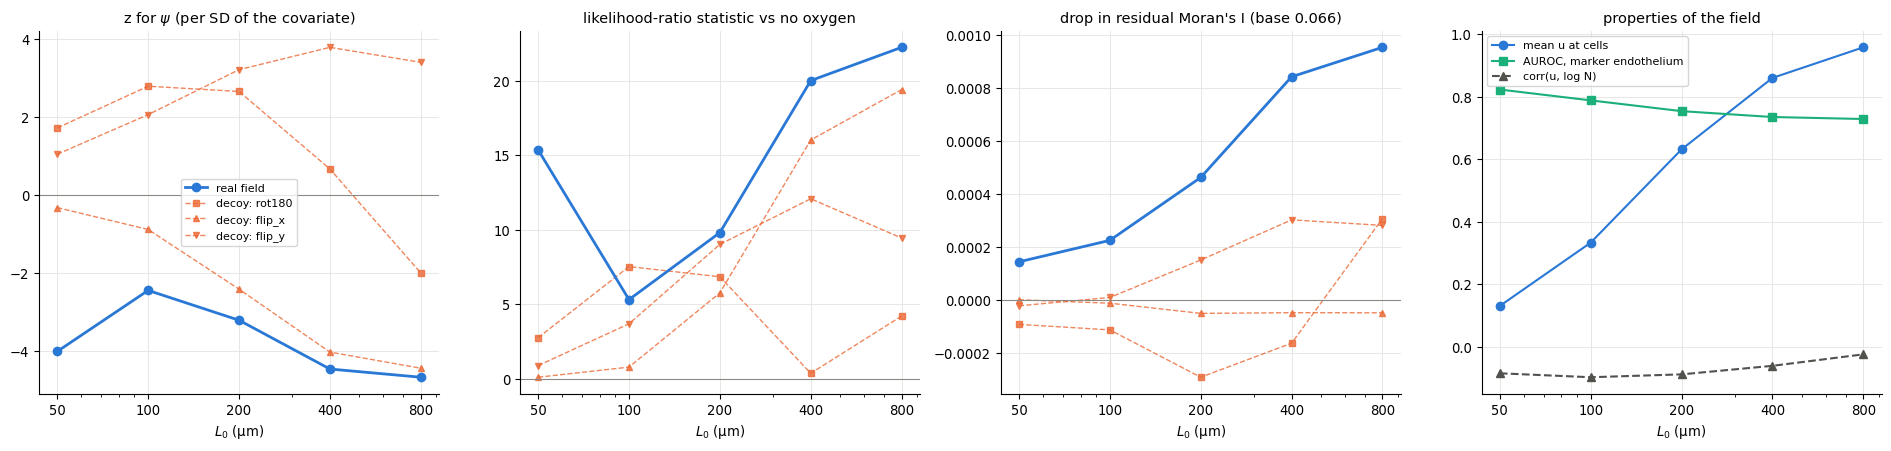

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
L = np.array(L0S)
dz = ox_tab[ox_tab["covariate"].isin(nbb.DECOYS)]
for ax, col, lab in ((axes[0], "z", r"z for $\psi$ (per SD of the covariate)"),
                     (axes[1], "LR vs no oxygen", "likelihood-ratio statistic vs no oxygen"),
                     (axes[2], "Moran reduction", f"drop in residual Moran's I (base {I_base:.3f})")):
    ax.plot(L, real[col], "o-", color=COL["real"], lw=2, label="real field", zorder=3)
    for k, mk in zip(nbb.DECOYS, ("s", "^", "v")):
        d = dz[dz["covariate"] == k].set_index("L0")[col]
        ax.plot(L, d, mk + "--", color=COL["decoy"], ms=5, lw=1, alpha=0.8, label=f"decoy: {k}")
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
    ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title(lab)
axes[0].legend(fontsize=8)
ax = axes[3]
ax.plot(L, field_tab["mean u"], "o-", color=COL["real"], label="mean u at cells")
ax.plot(L, [auc_tab.loc[f"u, L0 = {v:.0f}", "AUROC"] for v in L], "s-", color=COL["alt"], label="AUROC, marker endothelium")
ax.plot(L, field_tab["corr(u, log N)"], "^--", color=COL["base"], label="corr(u, log N)")
ax.set_xscale("log"); ax.set_xticks(L); ax.set_xticklabels([f"{v:.0f}" for v in L])
ax.set_xlabel(r"$L_0$ (µm)"); ax.set_title("properties of the field"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "oxygen_sweep")

### Reading §3

**The field now marks vessels.** The source scores AUROC 0.985 against
marker-identified endothelium, and $u$ scores 0.79 at $L_0$ = 100 µm. The decoys
score 0.5, and corr$(u, \log N) = -0.10$. The old SpaNorm field scored 0.515 and
correlated +0.49 with depth.

**The HIF gate still fails.** Across 100 µm tiles, Spearman$(u,$ HIF rate$)$ is
+0.27 (6 genes) and +0.20 (16 genes), and stays positive with depth ranked out.
The composite is dominated by NDRG1, LDHA and PFKFB3, which all rise with $u$.
The specific markers (CA9, BNIP3, SLC2A1) fall with $u$, as they should, but
only weakly.

**$u$ explains nothing about division beyond cell state.**
- $|\psi| \le 0.017$ per SD at every $L_0$, with a negative sign.
- At the production $L_0$ = 100 µm, the real field gains less likelihood than
  its 180° rotation (5.3 against 7.5).
- Only $L_0$ = 50 µm leads its decoys (15.4 against at most 2.8).
- At 400–800 µm the real field and the x-mirror are indistinguishable (20.0
  against 16.0, and 22.2 against 19.4).
- Residual Moran's I (0.066) falls by at most 0.001.
- Letting shallow cells consume oxygen changes nothing ($\psi$ −0.0103 against
  −0.0101).

The old notebook's 13× margin over the rotated decoy belonged to a field that
tracked depth. Short-range vessel proximity is already in $\eta$, through the
neighbours' Endothelial score.

**Decision (user, 2026-10-06): oxygen is dropped from every model.**

## 4. The annulus test: real neighbourhood effect, or segmentation spillover?

The 80 µm disc conflates two mechanisms:
- a **genuine neighbourhood effect**, where who surrounds a cell matters;
- **segmentation spillover**, where transcripts from a touching neighbour are
  assigned to this cell, so $\bar\phi$ partly echoes the cell's own
  mismeasured state.

Spillover is a contact artefact: it acts only between cells whose boundaries
touch. So the model is refit with $\bar\phi$ taken over successive rings, at
0–15, 15–30, 30–50, 50–80, 80–120 and 120–200 µm, and we watch the neighbour
effect move outward.

**The null.** Under pure spillover, a ring's coefficient is inherited from how
much its mean state still resembles the cell's own state:
$\hat c(r) = k\,\rho_\phi(r)$, where $\rho_\phi(r)$ is the PhiSpace correlogram
over every pair in the ring.

**Count matching.** A wide ring averages many more cells, so its $\bar\phi$ is
measured with less noise and suffers less regression dilution. That alone
inflates its coefficient. The count-matched control thins every ring at random
to the innermost ring's mean count, so all rings carry the same averaging noise.
This is the version to trust.

**Mechanics.**
- The neighbour pool is every typed cell, including the 2,107 outside the
  oxygen mask. Shallow cells are excluded, as in production.
- Each ring's mean is centred and projected exactly as the production
  $\bar\phi$; the rest of the model is the baseline (offset, no oxygen).
- All rings are fit on one cell set: cells with at least one typed neighbour
  in every ring.
- Effects are reported per SD of the ring mean, per cell type $k$:
  $\beta_k = (Qc)_k \cdot \mathrm{sd}(\bar\phi_k)$.
- The spillover χ² runs on the eight projected coordinates. Unlike the nine
  cell-type effects, which sum to zero, these are not linearly dependent.

In [18]:
pool = cells.loc[cells["typed"]].reset_index(drop=True)
pxy = pool[["x", "y"]].to_numpy(float)
P = pool[[f"phi_{t}" for t in TYPES]].to_numpy(float)
focal = pd.Series(np.arange(len(pool)), index=pool["cell_id"]).reindex(df["cell_id"]).to_numpy()
Pc = P - P.mean(0); Pq = Pc @ basis.Q_nbr
Zrho = np.column_stack([Pc / Pc.std(0), Pq / Pq.std(0)])      # 9 type scores, then 8 projected coords
cnt0 = nbb.ring_counts(pxy, focal, nbb.RINGS[0][1])
K_MATCH = int(round(cnt0.mean()))
ann = nbb.cached("annulus_rings", lambda: nbb.ring_means(pxy, P, focal, Zrho, max_neighbors=K_MATCH))
A = np.flatnonzero((ann["count"] > 0).all(0))
ring_lab = [f"{a:.0f}-{b:.0f}" for a, b in nbb.RINGS]
ring_tab = pd.DataFrame({"ring (µm)": ring_lab,
                         "mean neighbours": ann["count"].mean(1),
                         "count-matched": ann["count_matched"].mean(1),
                         "no neighbour %": 100 * (ann["count"] == 0).mean(1),
                         "pairs": ann["n_pairs"],
                         "rho (mean over types)": ann["rho"][:, :len(TYPES)].mean(1)}).set_index("ring (µm)")
print(f"count matching thins every ring to <= {K_MATCH} neighbours (the 0-15 µm mean is {cnt0.mean():.2f})")
print(f"annulus cell set: {len(A):,} cells ({100 * len(A) / n:.1f}%) with a typed neighbour in every ring")
ring_tab.round(3)

count matching thins every ring to <= 6 neighbours (the 0-15 µm mean is 6.31)
annulus cell set: 539,359 cells (96.0%) with a typed neighbour in every ring


,mean neighbours,count-matched,no neighbour %,pairs,rho (mean over types)
ring (µm),,,,,
0-15,6.312,4.590,3.484,3.5465e+06,0.256
15-30,18.665,5.727,0.969,1.0488e+07,0.191
30-50,42.175,5.893,0.272,2.3698e+07,0.157
50-80,98.498,5.976,0.033,5.5346e+07,0.131
80-120,193.199,5.996,0.009,1.0856e+08,0.106
120-200,583.917,6.000,0.001,3.2810e+08,0.078


In [19]:
ring_bar = {}
for r, lab in enumerate(ring_lab):
    for kind, S, Cn in (("naive", ann["sum"], ann["count"]), ("matched", ann["sum_matched"], ann["count_matched"])):
        ring_bar[(kind, lab)] = S[r][A] / Cn[r][A][:, None]
DA = nbb.subset(D, A)
ann_fit = {"none": nbb.cached("ann_nonbr", lambda: nbb.fit(nbb.subset(D, A, nbr=np.zeros_like(DA["nbr"])),
                                                           init=base_fit["params"], say=print, **BASE, **PEN)),
           "disc 0-80": nbb.cached("ann_disc80", lambda: nbb.fit(DA, init=base_fit["params"], say=print, **BASE, **PEN))}
for (kind, lab), Pb in ring_bar.items():
    ann_fit[(kind, lab)] = nbb.cached(f"ann_{kind}_{lab}", lambda Pb=Pb: nbb.fit(
        nbb.subset(D, A, nbr=nbb.project_nbr(Pb, basis)), init=base_fit["params"], say=print, **BASE, **PEN))

In [20]:
prod_bar = df[[f"nbr_phi_{j:02d}" for j in range(len(TYPES))]].to_numpy()[A]
def ring_effects(f, Pb):
    proj = nbb.project_nbr(Pb, basis); sdp = proj.std(0); sdt = Pb.std(0)
    vt, Ct = nbb.estimate(f, "c", basis.Q_nbr)
    vp, Cp = nbb.estimate(f, "c")
    U, V = f["params"]["U"], f["params"]["V"]
    sig = np.linalg.svd(U @ V.T * sdp[None, :], compute_uv=False)
    return dict(beta=vt * sdt, beta_se=np.sqrt(np.diag(Ct)) * sdt,
                cproj=vp * sdp, cproj_se=np.sqrt(np.diag(Cp)) * sdp, sigma1_B=sig[0], sigma2_B=sig[1])

ll0 = ann_fit["none"]["loglik"]
summ, coef_rows, per_type = [], [], {}
for kind in ("naive", "matched"):
    for r, lab in enumerate(ring_lab):
        f = ann_fit[(kind, lab)]; e = ring_effects(f, ring_bar[(kind, lab)])
        summ.append({"version": kind, "ring": lab, "mean |beta|": np.abs(e["beta"]).mean(),
                     "||beta||": np.linalg.norm(e["beta"]), "sigma1(B) per SD": e["sigma1_B"],
                     "neighbour-block LR": 2 * (f["loglik"] - ll0),
                     "rho": ann["rho"][r, :len(TYPES)].mean(), "converged": f["info"]["converged"]})
        per_type[(kind, lab)] = pd.Series(e["beta"], index=TYPES)
        for d in range(len(e["cproj"])):
            coef_rows.append({"version": kind, "r_inner": nbb.RINGS[r][0], "r_outer": nbb.RINGS[r][1],
                              "dim": f"q{d + 1}", "c": e["cproj"][d], "se": e["cproj_se"][d],
                              "rho_pair": ann["rho"][r, len(TYPES) + d]})
ed = ring_effects(ann_fit["disc 0-80"], prod_bar)
summ.append({"version": "production", "ring": "disc 0-80", "mean |beta|": np.abs(ed["beta"]).mean(),
             "||beta||": np.linalg.norm(ed["beta"]), "sigma1(B) per SD": ed["sigma1_B"],
             "neighbour-block LR": 2 * (ann_fit["disc 0-80"]["loglik"] - ll0), "rho": np.nan,
             "converged": ann_fit["disc 0-80"]["info"]["converged"]})
ann_tab = pd.DataFrame(summ)
for kind in ("naive", "matched"):
    m = ann_tab["version"] == kind
    b0, r0 = ann_tab.loc[m, "mean |beta|"].iloc[0], ann_tab.loc[m, "rho"].iloc[0]
    ann_tab.loc[m, "beta(r)/beta(0)"] = ann_tab.loc[m, "mean |beta|"] / b0
    ann_tab.loc[m, "rho(r)/rho(0)"] = ann_tab.loc[m, "rho"] / r0
ann_tab["ratio"] = ann_tab["beta(r)/beta(0)"] / ann_tab["rho(r)/rho(0)"]
coef = pd.DataFrame(coef_rows)
chi = {kind: spillover_chi2(coef[coef["version"] == kind]) for kind in ("naive", "matched")}
for kind, res in chi.items():
    print(f"spillover null c_d(r) = k_d rho_d(r), {kind}: chi2 = {res['chi2']:.0f} on {res['df']} df")
ann_tab.to_csv(OUT / "annulus.csv", index=False)
ann_tab.round(4)

spillover null c_d(r) = k_d rho_d(r), naive: chi2 = 724 on 40 df
spillover null c_d(r) = k_d rho_d(r), matched: chi2 = 256 on 40 df


,version,ring,mean |beta|,||beta||,sigma1(B) per SD,neighbour-block LR,rho,converged,beta(r)/beta(0),rho(r)/rho(0),ratio
0,naive,0-15,0.0375,0.1598,0.4570,5102.4488,0.2563,True,1.0000,1.0000,1.0000
1,naive,15-30,0.0319,0.1264,0.4199,4498.6567,0.1913,True,0.8528,0.7465,1.1423
2,naive,30-50,0.0286,0.1123,0.3665,3747.6917,0.1573,True,0.7638,0.6137,1.2447
3,naive,50-80,0.0277,0.1152,0.3790,3218.6259,0.1306,True,0.7397,0.5098,1.4511
4,naive,80-120,0.0277,0.1172,0.2978,2711.4546,0.1059,True,0.7396,0.4132,1.7897
5,naive,120-200,0.0317,0.1299,0.2207,2438.3937,0.0776,True,0.8476,0.3027,2.8003
6,matched,0-15,0.0363,0.1547,0.4531,4919.6697,0.2563,True,1.0000,1.0000,1.0000
7,matched,15-30,0.0253,0.1034,0.3545,3513.5644,0.1913,True,0.6957,0.7465,0.9318
8,matched,30-50,0.0187,0.0797,0.2676,2420.4362,0.1573,True,0.5140,0.6137,0.8376
9,matched,50-80,0.0161,0.0664,0.2432,1774.3179,0.1306,True,0.4446,0.5098,0.8721


In [21]:
# Per-type neighbour effects (per SD of the ring mean), count-matched rings, beside the production disc
bt = pd.DataFrame({lab: per_type[("matched", lab)] for lab in ring_lab})
bt["disc 0-80 (production)"] = pd.Series(ed["beta"], index=TYPES)
bt["120-200 / 0-15"] = bt["120-200"] / bt["0-15"]
bt.round(3)

,0-15,15-30,30-50,50-80,80-120,120-200,disc 0-80 (production),120-200 / 0-15
Endothelial,-0.047,-0.035,-0.030,-0.024,-0.022,-0.020,-0.052,0.422
CAFs,-0.019,-0.015,-0.008,-0.007,-0.004,-0.006,-0.011,0.288
PVL,-0.019,-0.009,-0.009,-0.007,-0.007,-0.005,0.003,0.267
B-cells,-0.007,-0.008,-0.008,-0.006,-0.009,-0.011,-0.006,1.557
T-cells,0.033,0.015,0.009,0.008,0.011,0.008,0.031,0.236
Myeloid,-0.033,-0.027,-0.009,-0.006,-0.003,0.002,-0.011,-0.054
Normal Epithelial,-0.013,-0.007,-0.008,-0.013,-0.012,-0.008,-0.042,0.611
Plasmablasts,0.021,0.026,0.019,0.018,0.015,0.014,0.038,0.673
Cancer Epithelial,0.135,0.086,0.068,0.056,0.050,0.035,0.107,0.263


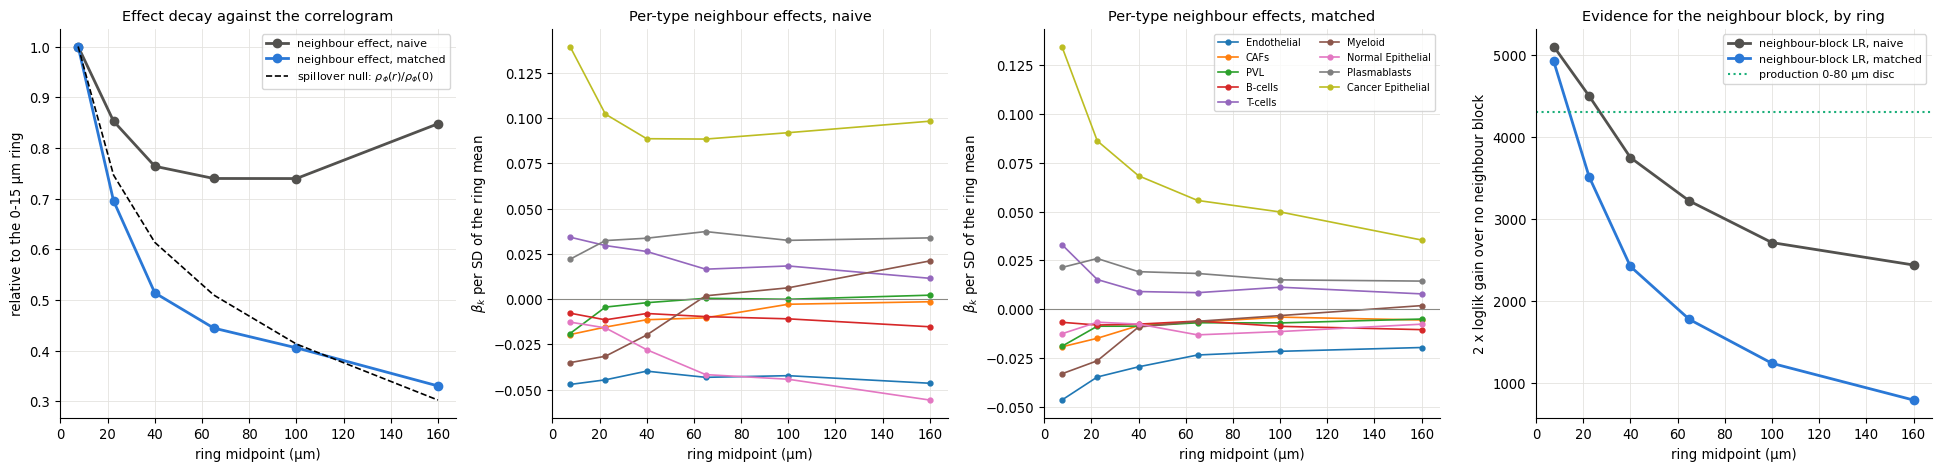

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(19.5, 4.8))
mid = np.array([(a + b) / 2 for a, b in nbb.RINGS])
ax = axes[0]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["beta(r)/beta(0)"], "o-", color=c, lw=2, label=f"neighbour effect, {kind}")
ax.plot(mid, ann_tab[ann_tab["version"] == "matched"]["rho(r)/rho(0)"], "k--", lw=1.2,
        label=r"spillover null: $\rho_\phi(r)/\rho_\phi(0)$")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("relative to the 0-15 µm ring"); ax.legend(fontsize=8)
ax.set_title("Effect decay against the correlogram")
for ax, kind in ((axes[1], "naive"), (axes[2], "matched")):
    M = pd.DataFrame({lab: per_type[(kind, lab)] for lab in ring_lab})
    for t in TYPES:
        ax.plot(mid, M.loc[t], "o-", ms=3.5, lw=1.2, label=t)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)")
    ax.set_ylabel(r"$\beta_k$ per SD of the ring mean"); ax.set_title(f"Per-type neighbour effects, {kind}")
axes[2].legend(fontsize=7, ncol=2)
ax = axes[3]
for kind, c in (("naive", COL["base"]), ("matched", COL["real"])):
    t = ann_tab[ann_tab["version"] == kind]
    ax.plot(mid, t["neighbour-block LR"], "o-", color=c, lw=2, label=f"neighbour-block LR, {kind}")
ax.axhline(ann_tab.loc[ann_tab["version"] == "production", "neighbour-block LR"].iloc[0], color=COL["alt"],
           ls=":", lw=1.5, label="production 0-80 µm disc")
ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel("2 x loglik gain over no neighbour block")
ax.set_title("Evidence for the neighbour block, by ring"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "annulus")

### Reading §4

**Naive rings repeat the old dilution artefact.** The effect dips to 0.74× by
50–80 µm, then climbs back to 0.85× at 120–200 µm, where each ring mean averages
584 cells instead of 6. Its ratio to the correlogram reaches 2.8.

**With count matching, the effect decays in step with the correlogram.** Each
ring holds at most 6 neighbours.

| ring (µm) | 0–15 | 15–30 | 30–50 | 50–80 | 80–120 | 120–200 |
|---|---|---|---|---|---|---|
| neighbour effect, relative | 1 | 0.70 | 0.51 | 0.44 | 0.41 | 0.33 |
| $\rho_\phi$, relative | 1 | 0.75 | 0.61 | 0.51 | 0.41 | 0.30 |
| ratio | 1 | 0.93 | 0.84 | 0.87 | 0.98 | 1.09 |

The old notebook's ratios of 1.1–1.4, read as an effect with its own range, do
not replicate. The χ² for exact proportionality is 256 on 40 df. It is
approximate (model-based SEs, every ring fit on the same cells), and the shape
is the robust part.

**What this says.** Spillover cannot act at 120–200 µm, yet a third of the
contact effect remains there (neighbour-block LR 792). The far effect is
regional composition, falling off as fast as composition decorrelates.
Meanwhile, the 0–15 µm ring alone (at most 6 cells) carries more evidence than
the whole 80 µm disc (LR 4,920 against 4,304).

**By cell type.** Cancer Epithelial carries the largest effect at every ring
(0.135 per SD at contact, 0.035 at 120–200 µm). The Endothelial effect is
negative throughout. The T-cell effect is a contact effect (0.033 to 0.008).
Plasmablasts are flattest (0.021 to 0.014).

## 5. Neighbourhood structure: how should $\bar\phi$ weight its neighbours?

§4 found that the contact ring carries the most information. The 80 µm disc
weights every neighbour equally, so it dilutes the closest cells with about
95 more distant ones. Here several alternatives compete as *predictors*, all
on the annulus cell set with the baseline model.

- **Uniform disc 0–80 µm.** Production.
- **Split, two blocks:** contact (0–15 µm) and regional (15–80 µm) means. Each
  gets its own main effect $c$ and its own rows of $V$, so the bilinear term
  reads $(\phi^\top U)(\bar\phi_\text{contact}^\top V_1 + \bar\phi_\text{regional}^\top V_2)$.
  This doubles the neighbour block (+24 parameters).
- **Split, three blocks:** adds a far block (80–200 µm), testing whether
  anything beyond 80 µm helps.
- **Six rings:** every annulus as its own block. This is the nonparametric
  distance profile and the upper bound on what any weighting could achieve
  (+120 parameters).
- **Exponential decay:**
  $\bar\phi_i = \sum_j w_{ij}\phi_j / \sum_j w_{ij}$ with
  $w_{ij} = e^{-d_{ij}/\ell}$ out to 200 µm, for
  $\ell \in \{5, 10, 20, 40, 80, 160\}$ µm. This has the same parameter count
  as the disc. $\ell$ is profiled over the grid: the best $\ell$ is the kernel
  the data prefer.

In-sample likelihood rewards the bigger blocks automatically, and spatial
autocorrelation makes AIC and BIC too lenient. The arbiter is therefore
**spatial 5-fold cross-validation**:
- folds are the stored map from the mixture's CV (contiguous blocks;
  `outputs/division_classifier/folds.parquet`, written on Spartan);
- the criterion is the held-out NB log-likelihood.

**A caution on contact terms.** Segmentation spillover acts exactly at contact,
so a model that up-weights touching cells can partly be fitting the artefact,
not biology. The split model makes the contact block explicit, so its effects
can be compared with the own-state effects.

In [23]:
def ring_mean(rs):
    S = sum(ann["sum"][r] for r in rs)[A]; Cn = sum(ann["count"][r] for r in rs)[A]
    return S / Cn[:, None]

print(f"0-80 µm disc rebuilt from the rings vs the production phibar: max |difference| "
      f"{np.abs(ring_mean([0, 1, 2, 3]) - prod_bar).max():.1e}")
BLOCKS = {"contact": ring_mean([0]), "regional": ring_mean([1, 2, 3]), "far": ring_mean([4, 5])}
ELLS = (5.0, 10.0, 20.0, 40.0, 80.0, 160.0)
kern = nbb.cached("kernel_means", lambda: nbb.kernel_means(pxy, P, focal, ELLS))
K_BAR = {ell: (kern["sum"][e] / kern["W"][e][:, None])[A] for e, ell in enumerate(ELLS)}
neff = {ell: float(np.median((kern["W"][e] ** 2 / kern["W2"][e])[A])) for e, ell in enumerate(ELLS)}

NBR = {"split: contact + regional": nbb.stack_nbr([BLOCKS["contact"], BLOCKS["regional"]], basis),
       "split: contact + regional + far": nbb.stack_nbr([BLOCKS["contact"], BLOCKS["regional"],
                                                         BLOCKS["far"]], basis),
       "six rings": nbb.stack_nbr([ring_mean([r]) for r in range(6)], basis)}
for ell in ELLS:
    NBR[f"exp, ell = {ell:.0f}"] = nbb.project_nbr(K_BAR[ell], basis)
TAG = {k: k.replace("split: ", "split_").replace(" + ", "_").replace(", ell = ", "_l").replace(" ", "_")
       for k in NBR}
nbr_fit = {"none": ann_fit["none"], "disc 0-80 (production)": ann_fit["disc 0-80"]}
for name, X in NBR.items():
    nbr_fit[name] = nbb.cached(f"nbr_{TAG[name]}", lambda X=X: nbb.fit(
        nbb.subset(D, A, nbr=X), init=base_fit["params"], say=print, **BASE, **PEN))

0-80 µm disc rebuilt from the rings vs the production phibar: max |difference| 2.3e-15


In [24]:
T_A = nbb.tiles(xc[A], yc[A]); yA = y[A]
ll_disc, ll_none = nbr_fit["disc 0-80 (production)"]["loglik"], nbr_fit["none"]["loglik"]
k_disc = nbb.n_params(nbr_fit["disc 0-80 (production)"]["params"])
rows = []
for name, f in nbr_fit.items():
    k = nbb.n_params(f["params"])
    rows.append({"model": name, "nbr width": f["params"]["c"].size, "k": k, "loglik": f["loglik"],
                 "gain vs disc": f["loglik"] - ll_disc, "dAIC vs disc": 2 * (k - k_disc) - 2 * (f["loglik"] - ll_disc),
                 "dBIC vs disc": (k - k_disc) * np.log(len(A)) - 2 * (f["loglik"] - ll_disc),
                 "neighbour LR": 2 * (f["loglik"] - ll_none),
                 "resid Moran I": nbb.tile_moran(nbb.pearson(yA, f["mu"], f["alpha"]), T_A, permutations=0)["I"],
                 "median n_eff": next((neff[e] for e in ELLS if name == f"exp, ell = {e:.0f}"), np.nan),
                 "converged": f["info"]["converged"]})
nbr_tab = pd.DataFrame(rows).set_index("model")
nbr_tab.to_csv(OUT / "neighbourhood_models.csv")
exp_names = [f"exp, ell = {e:.0f}" for e in ELLS]
BEST_EXP = max(exp_names, key=lambda m: nbr_tab.loc[m, "loglik"])
print(f"best exponential kernel in sample: {BEST_EXP} (median {nbr_tab.loc[BEST_EXP, 'median n_eff']:.1f} "
      f"effective neighbours, against ~{ann['count'][:4].sum(0)[A].mean():.0f} in the disc)")
nbr_tab.round(2)

best exponential kernel in sample: exp, ell = 10 (median 23.3 effective neighbours, against ~171 in the disc)


,nbr width,k,loglik,gain vs disc,dAIC vs disc,dBIC vs disc,neighbour LR,resid Moran I,median n_eff,converged
model,,,,,,,,,,
none,8,102,-585758.36,-2151.83,4303.66,4303.66,0.00,0.13,NaN,True
disc 0-80 (production),8,102,-583606.53,0.00,0.00,0.00,4303.66,0.09,NaN,True
split: contact + regional,16,126,-582523.27,1083.26,-2118.52,-1849.76,6470.18,0.08,NaN,True
split: contact + regional + far,24,150,-582246.71,1359.81,-2623.63,-2086.11,7023.29,0.08,NaN,True
six rings,48,222,-582108.91,1497.62,-2755.24,-1411.47,7298.91,0.08,NaN,True
"exp, ell = 5",8,102,-582799.85,806.68,-1613.36,-1613.36,5917.03,0.10,8.17,True
"exp, ell = 10",8,102,-582675.68,930.85,-1861.70,-1861.70,6165.36,0.09,23.35,True
"exp, ell = 20",8,102,-582970.37,636.16,-1272.31,-1272.31,5575.97,0.08,79.40,True
"exp, ell = 40",8,102,-583467.89,138.64,-277.28,-277.28,4580.94,0.09,273.62,True


In [25]:
# What each neighbourhood contributes, per SD of its mean, in cell-type coordinates
def type_effects(f, blocks, j):
    # per-type effects of stacked block j (8 columns each), per SD of that block's ring mean
    Qn = basis.Q_nbr; w = Qn.shape[1]
    v, C = nbb.estimate(f, "c")
    vj, Cj = v[j * w:(j + 1) * w], C[j * w:(j + 1) * w, j * w:(j + 1) * w]
    sd = blocks[j].std(0)
    return pd.DataFrame({"beta": (Qn @ vj) * sd, "se": np.sqrt(np.diag(Qn @ Cj @ Qn.T)) * sd}, index=TYPES)

own_sd = df[[f"phi_{j:02d}" for j in range(len(TYPES))]].to_numpy()[A].std(0)
own_eff = nbb.state_effects(nbr_fit["split: contact + regional"], basis, "a")["estimate"] * own_sd
sp2 = [BLOCKS["contact"], BLOCKS["regional"]]
eff_c = type_effects(nbr_fit["split: contact + regional"], sp2, 0)
eff_r = type_effects(nbr_fit["split: contact + regional"], sp2, 1)
split_tab = pd.DataFrame({"own (per SD)": own_eff, "contact": eff_c["beta"], "contact se": eff_c["se"],
                          "regional": eff_r["beta"], "regional se": eff_r["se"]})
print(f"corr(contact effects, own effects) = {np.corrcoef(split_tab['contact'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(regional, own) = {np.corrcoef(split_tab['regional'], split_tab['own (per SD)'])[0, 1]:+.3f}; "
      f"corr(contact, regional) = {np.corrcoef(split_tab['contact'], split_tab['regional'])[0, 1]:+.3f}")

r6 = [ring_mean([r]) for r in range(6)]
prof = pd.DataFrame({lab: type_effects(nbr_fit["six rings"], r6, r)["beta"] for r, lab in enumerate(ring_lab)})
ref = prof.iloc[:, 0].to_numpy()
ring_prof = pd.DataFrame({"||beta|| (per SD)": np.linalg.norm(prof.to_numpy(), axis=0),
                          "cosine with contact ring": [prof[c].to_numpy() @ ref / np.linalg.norm(prof[c]) / np.linalg.norm(ref)
                                                       for c in prof]}, index=ring_lab)
display(split_tab.round(3)); display(prof.round(3)); ring_prof.round(3)

corr(contact effects, own effects) = +0.777; corr(regional, own) = +0.516; corr(contact, regional) = +0.594


,own (per SD),contact,contact se,regional,regional se
Endothelial,-0.088,-0.035,0.003,-0.043,0.004
CAFs,-0.142,-0.020,0.003,-0.002,0.004
PVL,-0.024,-0.018,0.003,0.012,0.003
B-cells,0.102,0.002,0.003,-0.012,0.004
T-cells,0.156,0.029,0.004,0.017,0.005
Myeloid,-0.069,-0.032,0.003,0.001,0.004
Normal Epithelial,-0.038,-0.004,0.003,-0.035,0.006
Plasmablasts,0.017,0.008,0.003,0.035,0.004
Cancer Epithelial,0.157,0.123,0.005,0.034,0.007


,0-15,15-30,30-50,50-80,80-120,120-200
Endothelial,-0.029,-0.014,-0.006,-0.013,-0.009,-0.030
CAFs,-0.019,-0.009,-0.001,-0.001,0.006,0.003
PVL,-0.017,0.004,0.005,0.006,-0.000,0.003
B-cells,0.003,-0.006,-0.001,-0.000,0.003,-0.009
T-cells,0.029,0.010,0.005,-0.006,0.011,-0.008
Myeloid,-0.028,-0.022,-0.013,0.010,-0.002,0.031
Normal Epithelial,-0.005,0.003,-0.001,-0.003,-0.001,-0.037
Plasmablasts,0.007,0.012,0.009,0.007,-0.000,0.010
Cancer Epithelial,0.108,0.026,-0.010,-0.016,0.001,0.068


,||beta|| (per SD),cosine with contact ring
0-15,0.122,1.000
15-30,0.042,0.839
30-50,0.021,-0.158
50-80,0.025,-0.602
80-120,0.017,0.318
120-200,0.091,0.652


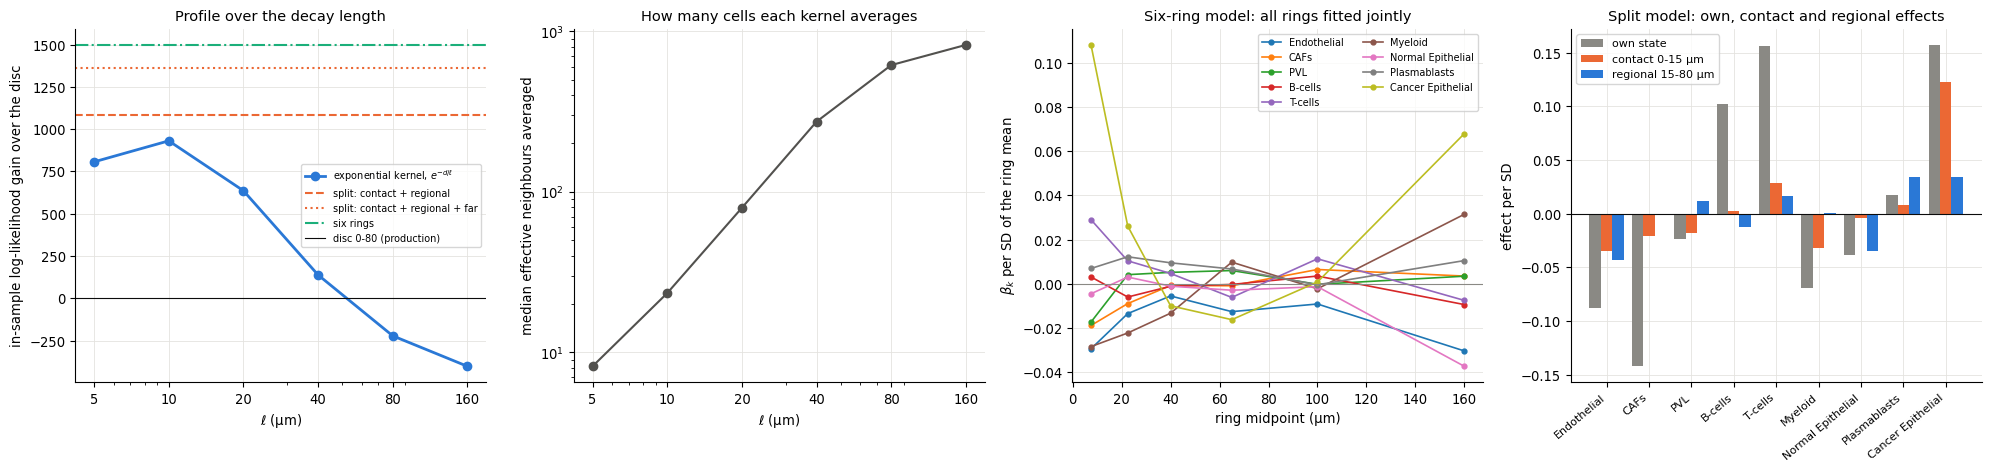

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
ax = axes[0]
ax.plot(ELLS, [nbr_tab.loc[m, "gain vs disc"] for m in exp_names], "o-", color=COL["real"], lw=2,
        label=r"exponential kernel, $e^{-d/\ell}$")
for m, ls, c in (("split: contact + regional", "--", COL["decoy"]), ("split: contact + regional + far", ":", COL["decoy"]),
                 ("six rings", "-.", COL["alt"])):
    ax.axhline(nbr_tab.loc[m, "gain vs disc"], ls=ls, color=c, lw=1.5, label=m)
ax.axhline(0, color=INK, lw=0.8, label="disc 0-80 (production)")
ax.set_xscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("in-sample log-likelihood gain over the disc")
ax.set_title("Profile over the decay length"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(ELLS, [neff[e] for e in ELLS], "o-", color=COL["base"])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(ELLS); ax.set_xticklabels([f"{e:.0f}" for e in ELLS])
ax.set_xlabel(r"$\ell$ (µm)"); ax.set_ylabel("median effective neighbours averaged"); ax.set_title("How many cells each kernel averages")
ax = axes[2]
for t in TYPES:
    ax.plot(mid, prof.loc[t], "o-", ms=3.5, lw=1.2, label=t)
ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel("ring midpoint (µm)"); ax.set_ylabel(r"$\beta_k$ per SD of the ring mean")
ax.set_title("Six-ring model: all rings fitted jointly"); ax.legend(fontsize=7, ncol=2)
ax = axes[3]
xx = np.arange(len(TYPES)); w = 0.27
ax.bar(xx - w, split_tab["own (per SD)"], w, color=MUTED, label="own state")
ax.bar(xx, split_tab["contact"], w, color=COL["decoy"], label="contact 0-15 µm")
ax.bar(xx + w, split_tab["regional"], w, color=COL["real"], label="regional 15-80 µm")
ax.axhline(0, color=INK, lw=0.8); ax.set_xticks(xx); ax.set_xticklabels(TYPES, rotation=40, ha="right", fontsize=8)
ax.set_ylabel("effect per SD"); ax.set_title("Split model: own, contact and regional effects"); ax.legend(fontsize=8)
fig.tight_layout(); savefig(fig, "neighbourhood_models")

### Spatial cross-validation

Five folds of contiguous blocks, from the stored fold map. Each model is refit
on four folds, warm-started from its full-data fit, and scored on the fifth.
Five candidates are compared:
- no neighbour block;
- the production disc;
- the two-block split;
- the best exponential kernel;
- the six-ring model.

The table gives the total held-out log-likelihood gain over the disc,
summed over all held-out cells, with the per-fold gains and a paired t across
folds. With five folds the t is a rough guide, so read it together with how
consistent the per-fold signs are.

In [27]:
fm = pd.read_parquet("outputs/division_classifier/folds.parquet")
assert (fm["cell_id"].astype(str).to_numpy() == df["cell_id"].astype(str).to_numpy()).all()
foldA = fm["fold"].to_numpy()[A]
print("fold sizes within the annulus set:", np.bincount(foldA).tolist())
CV = {"none": nbb.subset(D, A, nbr=np.zeros_like(DA["nbr"])), "disc 0-80 (production)": DA,
      "split: contact + regional": nbb.subset(D, A, nbr=NBR["split: contact + regional"]),
      BEST_EXP: nbb.subset(D, A, nbr=NBR[BEST_EXP]), "six rings": nbb.subset(D, A, nbr=NBR["six rings"])}
CVTAG = {"none": "none", "disc 0-80 (production)": "disc", **{k: TAG[k] for k in CV if k in TAG}}
cv_rows = []
for name, DD in CV.items():
    for fo_ in range(5):
        tr, te = np.flatnonzero(foldA != fo_), np.flatnonzero(foldA == fo_)
        g = nbb.cached(f"cv_{CVTAG[name]}_f{fo_}", lambda DD=DD, tr=tr, name=name: nbb.fit(
            nbb.subset(DD, tr), init=nbr_fit[name]["params"], se=False, **BASE, **PEN))
        ll = nbb.heldout_loglik(g, nbb.subset(DD, te))
        cv_rows.append({"model": name, "fold": fo_, "n_test": len(te), "heldout": ll.sum(),
                        "converged": g["info"]["converged"]})
cvd = pd.DataFrame(cv_rows)
piv = cvd.pivot(index="fold", columns="model", values="heldout")
gain = piv.sub(piv["disc 0-80 (production)"], axis=0)
cv_tab = pd.DataFrame({"total held-out gain vs disc": gain.sum(),
                       "per-fold gains": gain.apply(lambda s: " / ".join(f"{v:+.0f}" for v in s)),
                       "paired t": gain.mean() / (gain.std(ddof=1) / np.sqrt(5)),
                       "folds better than disc": (gain > 0).sum()})
cv_tab.loc["disc 0-80 (production)", ["paired t"]] = np.nan
print(f"all CV fits converged: {cvd['converged'].all()}")
cvd.to_csv(OUT / "neighbourhood_cv.csv", index=False)
cv_tab.sort_values("total held-out gain vs disc")

fold sizes within the annulus set: [113782, 100914, 113359, 107475, 103829]


all CV fits converged: True


,total held-out gain vs disc,per-fold gains,paired t,folds better than disc
model,,,,
none,-2082.8928,-425 / -487 / -418 / -320 / -433,-15.4155,0
disc 0-80 (production),0.0000,+0 / +0 / +0 / +0 / +0,NaN,0
"exp, ell = 10",932.4105,+179 / +184 / +196 / +198 / +175,40.0246,5
split: contact + regional,1043.3525,+248 / +209 / +174 / +200 / +212,17.4529,5
six rings,1305.8997,+326 / +230 / +228 / +226 / +297,12.4654,5


### Reading §5

**A short-range neighbourhood beats the uniform disc out of sample, on every
fold.**

| neighbourhood | parameters vs disc | held-out gain over the disc |
|---|---|---|
| none | −24 | −2,083 (worse on 5/5) |
| exponential kernel, $\ell$ = 10 µm (≈23 effective neighbours) | 0 | +932 (better on 5/5) |
| split: contact 0–15 + regional 15–80 µm | +24 | +1,043 (5/5) |
| six rings | +120 | +1,306 (5/5) |

- **The kernel profile peaks at $\ell$ = 10 µm.** From 80 µm upward it is worse
  than the disc.
- **The six-ring fit shows two scales.** The contact ring dominates
  (‖β‖ 0.12 per SD), and 15–30 µm adds a little in the same direction
  (cosine 0.84). The 30–120 µm rings add almost nothing, and the 120–200 µm ring
  returns (0.09, mostly Cancer Epithelial).
- **A caution.** Contact effects correlate +0.78 with own-state effects across
  cell types. Transcript spillover would do this, and so would proliferating
  cells clustering next to their own kind.

**Decision (user, 2026-10-07): the mixture's neighbour block is the
contact/regional split.** It isolates the spillover-prone contact signal in its
own block, so the regional block keeps its meaning as neighbourhood
composition. These fits used the old penalty (unwhitened, nuclear norm,
$\lambda$ = 10), which barely shrinks the NB mean.

## 6. Summary

| question | old notebook (SpaNorm scores) | this table | decision |
|---|---|---|---|
| depth: offset or free | $\theta \approx 0.70$, free it | $\hat\theta$ = 1.0005 ± 0.004; spline and per-type departures are not purely technical | offset (θ = 1) |
| state-dependent dispersion | helps | LR 290 on 8 df; misfit −9%; PIT slightly worse | constant α in the baseline |
| does the oxygen source mark vessels? | AUROC 0.515 | 0.985 (source), 0.79 ($u$) | — |
| does $u$ explain division beyond state? | z ≈ +15, ~13× the decoy | $|\psi| \le 0.017$ per SD; no margin over decoys at $L_0 \ge 100$ µm | oxygen dropped |
| annulus, count-matched | decays more slowly than $\rho_\phi$ | decays with $\rho_\phi$; contact ring most informative | — |
| neighbourhood structure | — | split +1,043, $\ell$ = 10 µm kernel +932, six rings +1,306 held out | contact/regional split |

What changed in the penalty and its selection, and why, is set out in the
[specification decisions document](https://claude.ai/code/artifact/70c686de-ba2d-4b2d-8d17-f29b5e2c2077). This notebook is to be rerun under the
new penalty once $\lambda$ has been chosen on the split model.